## Parcial: Aprendizaje Automático

**Título:** Predecir el consumo total de agua de Ushuaia del día siguiente

**Estudiante:** Tamara Roa

**Carrera:** Tecnicatura en Ciencia de Datos e IA - Centro Politécnico Superior Malvinas Argentinas

**Tipo de problema:** Supervisado — Regresión

**Índice**
- A. Problema, objetivos, origen de los datos y cambios respecto de las entregas anteriores (secciones 0 y 0.1)
- B. Preparación, exploración y transformación de los datos (secciones 1 a 7)
- C. Modelado, elección del modelo, evaluación y conclusiones (secciones 8 a 11)

**A: Descripción del problema, objetivo y Origen de los datos**



### 0. Problema
- **Problema:** predecir el consumo total de agua de Ushuaia del día siguiente (m³/día, variable numérica continua).
- **Unidad de observación:** una fila = un día de la ciudad (suma de las plantas 2, 3 y 4).
- **Momento de predicción:** al cierre de cada día (00:00), con lo ocurrido hasta ese momento. Horizonte: 24 h.
- **Información disponible:** solo datos hasta el cierre de hoy (consumo pasado, turbidez, caudal, volumen almacenado y clima de hoy). No se usa ninguna medición de mañana; lo único que se conoce de antemano es el calendario (día de la semana y mes).
- **Variable a predecir (y):** consumo estimado por balance, no medido.
- **Evaluación:** partición temporal (entrena hasta el 29/04/2026, prueba desde el 01/05/2026). El modelo se elige con validación cruzada temporal dentro del entrenamiento; el período de prueba se usa una sola vez, al final. Todo se compara contra tres referencias simples. Métricas: MAE, RMSE y R².
- **Modelos a utilizar:** Ridge, Random Forest y KNN.

**Objetivo general.** Estimar el consumo diario de agua de Ushuaia y predecir el del día siguiente con modelos de regresión.

**Objetivos específicos.**
1. Estimar el consumo diario por balance entre el agua que ingresa y la variación del volumen de las cisternas de las plantas 2, 3 y 4.
2. Explorar los datos y su relación con la turbidez, el caudal, el calendario y el clima.
3. Comparar Ridge, Random Forest y KNN con tres referencias simples.
4. Evaluar los modelos con MAE, RMSE y R² y analizar sus errores.
5. Analizar, como complemento, qué ocurre con las reservas de la Planta 3 después de un episodio de turbidez alta.

**Relevancia.** No existe una medición directa del consumo de la ciudad; conocerlo y anticiparlo ayuda a planificar la producción y el almacenamiento de agua.

### 0.1 Origen de los datos
Fuente de telemetría de las tres (03) plantas: Dirección Provincial de Obras y Servicios Sanitarios.

Fecha de obtención: Octubre 2026.

Fuente del clima: Servicio Meteorológico Nacional, estación Ushuaia Aeropuerto.
Fecha de obtención: Noviembre 2026.

Período cubierto: 01/01/2025 00:00 a 31/07/2026 22:00 (las tres plantas); la Planta 2 llega hasta el 31/08/2026. Una lectura cada 2 horas, hora de Ushuaia (3 horas menos que la hora universal, UTC).

Contexto: las plantas 2, 3 y 4 captan el agua cruda, la procesan y la envían a las cisternas que abastecen a la ciudad.

Los archivos de data/processed ya tienen una lectura cada 2 horas e incluyen dos indicadores: caudal_anomalo (lecturas de caudal sospechosas) y turbidez_999 (lecturas en el tope del sensor: la turbidez fue de 999 NTU o más). El detalle de cada columna está en docs/diccionario_datos.md.

**B: Descripción, exploración, visualizaciones y transformación de los datos**



## 1. Preparación del entorno
Se definen las carpetas del proyecto (data/raw, data/processed y reports/figures) y se verifica que existan los archivos necesarios antes de cargarlos.

In [1]:
# entorno y rutas
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/agua_ushuaia")   # carpeta del proyecto en tu Drive
except ImportError:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

PROC = RAIZ / "data" / "processed"
RAW  = RAIZ / "data" / "raw"
FIG  = RAIZ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

archivos = [PROC / "planta2_turbidez_cisternas_2h.csv",
            PROC / "planta3_2h.csv",
            PROC / "planta4_turbidez_cisternas_2h.csv",
            RAW  / "Temperatura, humedad y precipitaciones.xlsx"]
for a in archivos:
    print("OK     " if a.exists() else "FALTA  ", a.relative_to(RAIZ))

Mounted at /content/drive
OK      data/processed/planta2_turbidez_cisternas_2h.csv
OK      data/processed/planta3_2h.csv
OK      data/processed/planta4_turbidez_cisternas_2h.csv
OK      data/raw/Temperatura, humedad y precipitaciones.xlsx


## 2. Carga y revisión de los datos
Se cargan las tablas de las plantas 2, 3 y 4 (lecturas cada 2 horas, con turbidez, caudal de ingreso y nivel de cisternas) para verificar filas, período y columnas. La hora se convierte a hora de Ushuaia.

In [2]:
# carga y revisión de los datos
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# Nombres de archivos
ARCH = {2: "planta2_turbidez_cisternas_2h.csv",
        3: "planta3_2h.csv",
        4: "planta4_turbidez_cisternas_2h.csv"}

plantas = {}
for p, nombre in ARCH.items():
    d = pd.read_csv(PROC / nombre)
    d["fecha_hora"] = (pd.to_datetime(d["fecha_hora"], utc=True)
                         .dt.tz_convert("America/Argentina/Ushuaia")
                         .dt.tz_localize(None))
    plantas[p] = d.set_index("fecha_hora").sort_index()

# Resumen de cada planta
resumen = pd.DataFrame({f"Planta {p}": {
    "filas": len(d),
    "desde": d.index.min(),
    "hasta": d.index.max(),
    "turbidez (lecturas)": d.turbidez_ntu.notna().sum(),
    "caudal (lecturas)": d.caudal_ls.notna().sum(),
    "caudal medio (L/s)": round(d.caudal_ls.mean(), 1)} for p, d in plantas.items()}).T
resumen

,filas,desde,hasta,turbidez (lecturas),caudal (lecturas),caudal medio (L/s)
Planta 2,7296,2025-01-01 00:00:00,2026-08-31 22:00:00,7280,7270,306.2
Planta 3,6924,2025-01-01 00:00:00,2026-07-31 22:00:00,6915,6903,130.7
Planta 4,6924,2025-01-01 00:00:00,2026-07-31 22:00:00,6900,6893,70.6


## 3. Volumen almacenado por planta
Para cada planta se calcula el volumen total almacenado (m³) como la suma de las cisternas con lectura en toda la serie. Se usa siempre el mismo conjunto de cisternas para que la variación del volumen entre dos momentos refleje agua que entra o sale, y no un cambio en cuántas cisternas se suman.

In [3]:
# volumen almacenado por planta (m³)
plantas[2]["vol"] = plantas[2][["vol_m3_a", "vol_m3_b"]].sum(axis=1, min_count=2)   # si falta una, queda sin dato
plantas[3]["vol"] = plantas[3]["vol_obj_m3"]                                        # suma de 400, 500, 2000, 5000 y Terrazas
plantas[4]["vol"] = plantas[4]["vol_m3_principal"]

# Verificación: la columna de la Planta 3 debe coincidir con la suma de sus 5 cisternas
chequeo = plantas[3][["vol_m3_400", "vol_m3_500", "vol_m3_2000", "vol_m3_5000", "vol_m3_terrazas"]].sum(axis=1, min_count=5)
print("Diferencia máxima Planta 3:", (chequeo - plantas[3]["vol"]).abs().max())

for p, d in plantas.items():
    print(f"Planta {p}: volumen medio {d.vol.mean():,.0f} m³ | sin dato: {d.vol.isna().sum()} de {len(d)}")

Diferencia máxima Planta 3: 9.094947017729282e-13
Planta 2: volumen medio 7,289 m³ | sin dato: 39 de 7296
Planta 3: volumen medio 6,363 m³ | sin dato: 149 de 6924
Planta 4: volumen medio 1,140 m³ | sin dato: 28 de 6924


### 3.1 Resumen general de los datos crudos
Antes de calcular nada, se muestra qué hay en cada archivo: cuántos registros y columnas tiene, de qué fecha a qué fecha va y cuántos datos le faltan. Los archivos se leen tal como están guardados, sin transformar.

In [4]:
# Resumen general de todos los archivos de entrada
ARCH_CLIMA = "Temperatura, humedad y precipitaciones.xlsx"
archivos = {f"Planta {p}": pd.read_csv(PROC / n) for p, n in ARCH.items()}
archivos["Clima"] = pd.read_excel(RAW / ARCH_CLIMA)

def rango_fechas(df, nombre):
    col = df.columns[0] if nombre == "Clima" else "fecha_hora"
    if nombre == "Clima":
        f = pd.to_datetime(df[col], format="%d.%m.%Y %H:%M")
    else:
        f = pd.to_datetime(df[col].str[:19])
    return f.min(), f.max()

filas = []
for nombre, df in archivos.items():
    d0, d1 = rango_fechas(df, nombre)
    filas.append({
        "archivo": nombre,
        "registros": len(df),
        "columnas": df.shape[1],
        "numéricas": df.select_dtypes("number").shape[1],
        "verdadero/falso": df.select_dtypes("bool").shape[1],
        "desde": d0.date(), "hasta": d1.date(),
        "celdas sin dato (%)": round(df.isna().mean().mean() * 100, 1),
        "filas con algún faltante (%)": round(df.isna().any(axis=1).mean() * 100, 1),
        "filas duplicadas": int(df.duplicated().sum())})
resumen_archivos = pd.DataFrame(filas).set_index("archivo")
print(resumen_archivos.T.to_string())

archivo                         Planta 2    Planta 3    Planta 4       Clima
registros                           7296        6924        6924       16055
columnas                              13          23          13           4
numéricas                              9          20           9           2
verdadero/falso                        3           2           3           0
desde                         2025-01-01  2025-01-01  2025-01-01  2025-01-01
hasta                         2026-08-31  2026-07-31  2026-07-31  2026-11-06
celdas sin dato (%)                  0.2         6.5        10.3        21.5
filas con algún faltante (%)         0.8        24.0        66.0        85.6
filas duplicadas                       0           0           0           0


**Interpretación.** Hay 7.296 registros de la Planta 2 y 6.924 de las plantas 3 y 4, con una lectura cada 2 horas desde el 01/01/2025 (hasta el 31/08/2026 en la Planta 2 y el 31/07/2026 en las otras dos). El clima tiene 16.055 registros horarios hasta el 06/11/2026. No hay filas duplicadas. Los faltantes se concentran en pocas columnas (cisternas con registro parcial y precipitación), por lo que el porcentaje de filas incompletas es mucho mayor que el de celdas vacías.

In [5]:
# Función para ver, de cada archivo, filas, columnas, tipos, faltantes y rango de valores
def ficha(df, nombre):
    print("=" * 70)
    print(nombre)
    print("=" * 70)
    print(f"Filas: {len(df):,} | Columnas: {df.shape[1]}")
    t = pd.DataFrame({
        "tipo":     df.dtypes.astype(str),
        "con dato": df.notna().sum(),
        "faltan":   df.isna().sum(),
        "% falta":  (df.isna().mean() * 100).round(1),
        "mínimo":   df.min(numeric_only=True),
        "mediana":  df.median(numeric_only=True),
        "máximo":   df.max(numeric_only=True),
    })
    pd.set_option("display.max_rows", None, "display.max_columns", None, "display.width", 200)
    print(t.round(1).to_string())
    return t

In [6]:
# Archivos de las plantas, tal como están guardados (sin transformar)
crudos = {p: pd.read_csv(PROC / nombre) for p, nombre in ARCH.items()}

for p, df in crudos.items():
    ficha(df, f"PLANTA {p}  ({ARCH[p]})")
    print()

PLANTA 2  (planta2_turbidez_cisternas_2h.csv)
Filas: 7,296 | Columnas: 13
                        tipo  con dato  faltan  % falta  mínimo  mediana  máximo
caudal_anomalo          bool      7296       0      0.0   False      0.0    True
caudal_ls            float64      7270      26      0.4   150.0    315.0   448.0
caudal_ls_crudo      float64      7282      14      0.2     0.0    315.0   448.0
fecha_hora            object      7296       0      0.0     NaN      NaN     NaN
n_cisternas_validas    int64      7296       0      0.0       0      2.0       2
nivel_pct_a          float64      7269      27      0.4     5.4     75.0    92.4
nivel_pct_b          float64      7271      25      0.3    0.74     77.4   127.8
turbidez_999            bool      7296       0      0.0   False      0.0    True
turbidez_ntu         float64      7280      16      0.2     0.3      3.5   999.0
vol_m3_a             float64      7269      27      0.4   270.0   3750.0  4620.0
vol_m3_b             float64      7

### 3.2 Faltantes y valores atípicos
Se muestran solo las columnas con 1 % o más de datos faltantes y los valores atípicos relevantes, indicando en cada caso si la columna **se usa en el modelo**. No se elimina ni se completa ningún dato en esta etapa. Un valor atípico estadístico no es necesariamente un error: puede ser un valor real pero poco frecuente.

Columnas con 1 % o más de datos faltantes:
 archivo             columna  % sin dato ¿se usa en el modelo?                                             motivo
   Clima              precip        85.5                    No                           precipitación incompleta
Planta 4 vol_m3_costa_susana        65.8                    No cisterna con registro parcial; no entra al volumen
Planta 3       vol_m3_reinas        23.5                    No cisterna con registro parcial; no entra al volumen
Planta 3          vol_m3_640        23.4                    No cisterna con registro parcial; no entra al volumen
Planta 3    vol_m3_lenadores        23.3                    No cisterna con registro parcial; no entra al volumen
Planta 3     vol_m3_terrazas         1.9                    Sí                                             se usa

Máximo de faltantes entre las columnas que SÍ se usan:
  Planta 2: 0.4 %
  Planta 3: 1.9 %
  Planta 4: 0.4 %
  Clima: 0.3 %

Valores atípicos y valores imposi

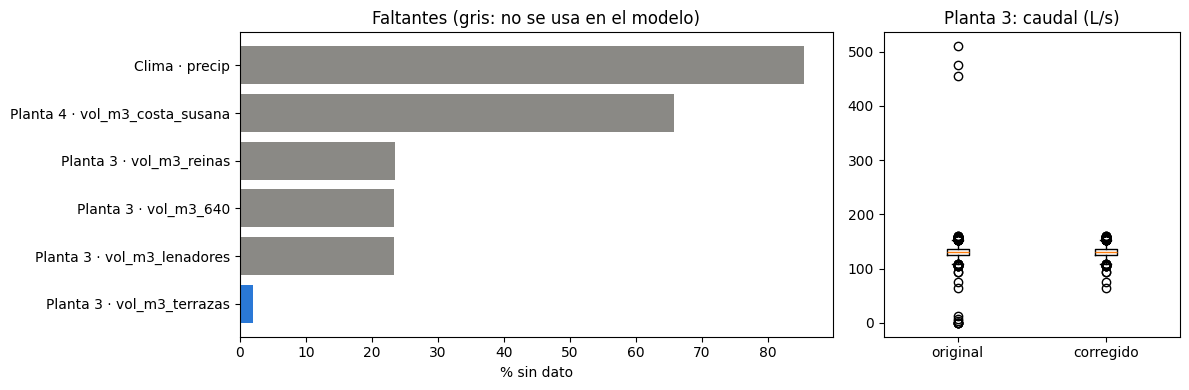

In [7]:
# Faltantes y valores atípicos:
archivos["Clima"].columns = ["fecha_hora", "temp", "hum", "precip"]

# Columnas que realmente entran al modelo
USADAS = {"Planta 2": ["turbidez_ntu", "caudal_ls", "vol_m3_a", "vol_m3_b"],
          "Planta 3": ["turbidez_ntu", "caudal_ls", "vol_m3_400", "vol_m3_500", "vol_m3_2000", "vol_m3_5000", "vol_m3_terrazas"],
          "Planta 4": ["turbidez_ntu", "caudal_ls", "vol_m3_principal"],
          "Clima":    ["temp", "hum"]}

# --- Faltantes: solo las columnas con 1 % o más sin dato ---
filas = []
for nombre, df in archivos.items():
    for c in df.columns:
        if c.startswith("nivel_pct_") or c == "vol_obj_m3":      # repiten a los volúmenes (m³): no se listan
            continue
        pct = df[c].isna().mean() * 100
        if pct >= 1:
            usa = c in USADAS[nombre]
            motivo = ("se usa" if usa else
                      "precipitación incompleta" if c == "precip" else
                      "cisterna con registro parcial; no entra al volumen" if c.startswith("vol_") else "")
            filas.append({"archivo": nombre, "columna": c, "% sin dato": round(pct, 1),
                          "¿se usa en el modelo?": "Sí" if usa else "No", "motivo": motivo})
faltantes = pd.DataFrame(filas).sort_values("% sin dato", ascending=False)
print("Columnas con 1 % o más de datos faltantes:")
print(faltantes.to_string(index=False))
print("\nMáximo de faltantes entre las columnas que SÍ se usan:")
for nombre, cols in USADAS.items():
    print(f"  {nombre}: {archivos[nombre][cols].isna().mean().max() * 100:.1f} %")

# --- Atípicos: solo los casos relevantes ---
def pct_iqr(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); r = q3 - q1
    return ((s < q1 - 1.5 * r) | (s > q3 + 1.5 * r)).mean() * 100

filas = []
for p in (2, 3, 4):
    df = archivos[f"Planta {p}"]
    niv = [c for c in df.columns if c.startswith("nivel_pct_")]
    filas.append({"archivo": f"Planta {p}",
                  "turbidez atípica (IQR, %)": round(pct_iqr(df.turbidez_ntu), 1),
                  "turbidez en el tope del sensor (≥ 999 NTU)": int((df.turbidez_ntu >= 999).sum()),
                  "caudal original anómalo (lecturas)": int(df.caudal_anomalo.sum()),
                  "nivel de cisterna > 100 % (lecturas)": int(sum((df[c] > 100).sum() for c in niv))})
cl = archivos["Clima"]
filas.append({"archivo": "Clima", "turbidez atípica (IQR, %)": "–", "turbidez en el tope del sensor (≥ 999 NTU)": "–",
              "caudal original anómalo (lecturas)": "–", "nivel de cisterna > 100 % (lecturas)": "–"})
print("\nValores atípicos y valores imposibles:")
print(pd.DataFrame(filas).set_index("archivo").to_string())
print(f"Clima: temperatura entre {cl.temp.min():.1f} y {cl.temp.max():.1f} °C; humedad entre {cl.hum.min():.0f} y {cl.hum.max():.0f} %")

# --- Gráfico: faltantes (azul = se usa, gris = no se usa) y caudal de la Planta 3 antes y después de la corrección ---
fig, ax = plt.subplots(1, 2, figsize=(12, 0.3 * len(faltantes) + 2.2), gridspec_kw={"width_ratios": [2, 1]})
f = faltantes.sort_values("% sin dato")
ax[0].barh(f["archivo"] + " · " + f["columna"], f["% sin dato"],
           color=["#2a78d6" if u == "Sí" else "#8a8985" for u in f["¿se usa en el modelo?"]])
ax[0].set_xlabel("% sin dato"); ax[0].set_title("Faltantes (gris: no se usa en el modelo)")
p3 = archivos["Planta 3"]
ax[1].boxplot([p3.caudal_ls_crudo.dropna(), p3.caudal_ls.dropna()])
ax[1].set_xticklabels(["original", "corregido"]); ax[1].set_title("Planta 3: caudal (L/s)")
plt.tight_layout(); plt.savefig(FIG / "faltantes_y_atipicos.png", dpi=150); plt.show()

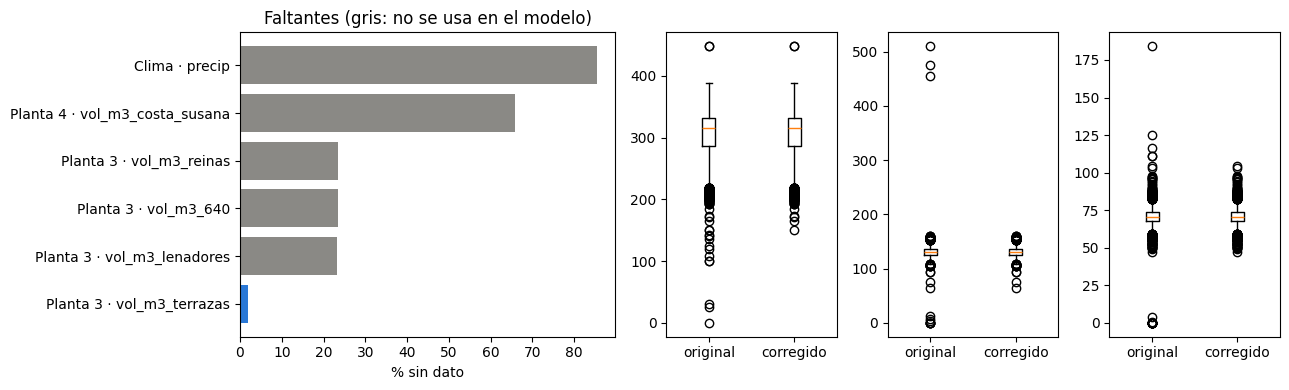

In [8]:
# --- Gráfico: faltantes (azul = se usa, gris = no se usa) y caudal de cada planta antes y después de la corrección ---
fig = plt.figure(figsize=(13, 0.3 * len(faltantes) + 2.2))
gs = fig.add_gridspec(1, 4, width_ratios=[2.2, 1, 1, 1])
ax0 = fig.add_subplot(gs[0])
f = faltantes.sort_values("% sin dato")
ax0.barh(f["archivo"] + " · " + f["columna"], f["% sin dato"],
         color=["#2a78d6" if u == "Sí" else "#8a8985" for u in f["¿se usa en el modelo?"]])
ax0.set_xlabel("% sin dato"); ax0.set_title("Faltantes (gris: no se usa en el modelo)")
for k, p in enumerate((2, 3, 4)):
    a = fig.add_subplot(gs[k + 1])
    d = archivos[f"Planta {p}"]
    a.boxplot([d.caudal_ls_crudo.dropna(), d.caudal_ls.dropna()])
    a.set_xticklabels(["original", "corregido"])
plt.tight_layout(); plt.savefig(FIG / "faltantes_y_atipicos.png", dpi=150); plt.show()

Interpretación. Lo que más falta está en columnas que no uso en el modelo (precipitación y algunas cisternas con registro parcial). En las columnas que sí uso falta como máximo un 1,9 %, y no lo completé: esos días quedan afuera del análisis.

Los picos de turbidez los conservé porque son reales y es justo lo que quiero estudiar. Eso incluye las lecturas de 999 NTU: son el tope del sensor, es decir, la turbidez real fue de 999 NTU o más. No son un error, sino un valor que el sensor no puede medir completo, así que las conservo con el valor 999 como piso.

El caudal tiene pocas lecturas anómalas (ceros y valores muy altos, como 510 L/s en la Planta 3, donde lo normal es cerca de 130). No las corregí: las marqué en caudal_anomalo y las dejé sin dato en caudal_ls. Falta confirmar con operaciones si los ceros son paradas reales de la planta, y qué pasó con dos lecturas de la cisterna B de la Planta 2 por encima del 100 %.
Original: caudal tal como vino en los datos. Corregido: sin las lecturas anómalas, que se dejaron sin dato

## 4. Consumo diario estimado por planta
No hay una medición directa del consumo, por lo que se estima por balance: consumo del día = agua que ingresa en el día − variación del volumen almacenado. El ingreso se obtiene del caudal medio diario (L/s × 86,4 = m³/día) y la variación, de la diferencia de volumen entre las 00:00 de dos días consecutivos. Los días con menos de 10 lecturas de caudal o sin volumen se dejan sin dato, sin imputar. En este paso también se resume la turbidez de cada día (media y máxima). Las lecturas de 999 NTU se conservan: en esos días la turbidez real fue igual o mayor, así que la media y la máxima de ese día son un piso del valor real.

In [9]:
# consumo diario estimado de cada planta (m³/día)
filas = []
for p, d in plantas.items():
    dia = d.index.floor("D")
    q = d.groupby(dia).agg(caudal=("caudal_ls", "mean"),
                           n_q=("caudal_ls", "count"),
                           turb=("turbidez_ntu", "mean"),            # 999 = tope del sensor (turbidez ≥ 999): se conserva
                           turb_max=("turbidez_ntu", "max"))
    v0 = d.vol[d.index.hour == 0]          # volumen a las 00:00
    v0.index = v0.index.floor("D")
    v0 = v0.reindex(q.index)
    q["vol"] = v0
    q["cons"] = q.caudal * 86.4 - (v0.shift(-1) - v0)   # entra - (vol. mañana - vol. hoy)
    q.loc[q.n_q < 10, "cons"] = np.nan                  # sin imputar
    filas.append(q.add_suffix(f"_{p}"))

FIN = "2026-07-31 23:59"                    # último día con datos en las tres plantas
D0 = pd.concat(filas, axis=1)
D0 = D0[D0.index <= FIN]
print("Días con alguna lectura en el tope del sensor (999 NTU):", {f"Planta {p}": int((D0[f"turb_max_{p}"] >= 999).sum()) for p in (2, 3, 4)})
D0[["cons_2", "cons_3", "cons_4"]].describe().round(0)

Días con alguna lectura en el tope del sensor (999 NTU): {'Planta 2': 1, 'Planta 3': 3, 'Planta 4': 1}


,cons_2,cons_3,cons_4
count,570.0,555.0,572.0
mean,26634.0,11307.0,6098.0
std,1818.0,797.0,230.0
min,15477.0,6689.0,5559.0
25%,25840.0,10822.0,5939.0
50%,26929.0,11350.0,6068.0
75%,27776.0,11831.0,6232.0
max,31605.0,14591.0,7088.0


**Interpretación.** Se obtuvo el consumo diario estimado de cada planta: 570 días con dato en la Planta 2, 555 en la Planta 3 y 572 en la Planta 4, de los 577 del período. La Planta 3 es la que más días pierde (22), por sus faltantes de volumen. Los días sin dato no se completan.

El consumo medio es de ≈ 26.600 m³/día en la Planta 2, ≈ 11.300 en la Planta 3 y ≈ 6.100 en la Planta 4. Sumadas dan ≈ 44.000 m³/día, que es el nivel de consumo de la ciudad. La Planta 2 aporta cerca del 60 %, la Planta 3 el 26 % y la Planta 4 el 14 %.

La variación entre días es chica: el desvío es de ≈ 7 % del promedio en las plantas 2 y 3 y de ≈ 4 % en la Planta 4, y la mediana está muy cerca de la media en las tres. Eso indica un consumo estable día a día. Los valores mínimos (por ejemplo ≈ 15.500 m³ en la Planta 2) se alejan bastante del promedio y corresponden a días puntuales a revisar; por ahora se conservan.

El consumo de la ciudad se calcula después, sumando las tres plantas solo en los días en que las tres tienen dato.

El consumo mínimo de la Planta 2 (≈ 15.500 m³ el 10/11/2025) forma parte de un período de tres días de baja marcada (9 al 11/11/2025). Se conserva en el análisis; su causa se desconoce y debe confirmarse con operaciones.

## 5. Consumo diario de la ciudad
El consumo de Ushuaia se obtiene sumando el consumo estimado de las plantas 2, 3 y 4. Solo se calcula en los días en que las tres plantas tienen dato; no se rellenan los faltantes. También se resumen, por día, la turbidez (media y máxima), el caudal total de ingreso y el volumen almacenado total, que serán las variables explicativas.

In [10]:
# consumo diario de la ciudad y variables diarias
D = pd.DataFrame(index=D0.index)
D["cons"]      = D0[["cons_2", "cons_3", "cons_4"]].sum(axis=1, min_count=3)   # exige las 3 plantas
D["turb_mean"] = D0[["turb_2", "turb_3", "turb_4"]].mean(axis=1)
D["turb_max"]  = D0[["turb_max_2", "turb_max_3", "turb_max_4"]].max(axis=1)
D["caudal"]    = D0[["caudal_2", "caudal_3", "caudal_4"]].sum(axis=1, min_count=3)
D["vol"]       = D0[["vol_2", "vol_3", "vol_4"]].sum(axis=1, min_count=3)

print("Días:", len(D), "| con consumo calculable:", D.cons.notna().sum(), "| sin dato:", D.cons.isna().sum())
D.cons.describe().round(0)

Días: 577 | con consumo calculable: 545 | sin dato: 32


,cons
count,545.0
mean,44052.0
std,1994.0
min,33029.0
25%,43112.0
50%,44252.0
75%,45344.0
max,50960.0


**Interpretación.** El período tiene 577 días, de los cuales 545 tienen consumo calculable para la ciudad y 32 quedan sin dato (5,5 %). Esos días no se completan: son días en que alguna de las tres plantas no tiene dato, y como el consumo de la ciudad es la suma de las tres, se necesita que estén las tres.

El consumo medio de Ushuaia es de ≈ 44.050 m³/día. La mitad de los días está entre ≈ 43.100 y ≈ 45.300 m³ (percentiles 25 y 75), y la mediana (44.250) es casi igual al promedio, por lo que la distribución es bastante simétrica. El desvío estándar es de ≈ 2.000 m³, alrededor del 4,5 % del promedio: el consumo de la ciudad es muy estable de un día a otro.

Los extremos se alejan de lo habitual: el mínimo es de ≈ 33.000 m³ (en noviembre de 2025) y el máximo de ≈ 51.000 m³ (en julio de 2026). Son pocos días puntuales; se conservan y se tratan como atípicos a confirmar. Esto ya anticipa que predecir el consumo de mañana no será difícil de acercarse, pero sí difícil de mejorar: repetir el valor de hoy ya da un error chico.

## 6. Clima diario
Se carga la temperatura y la humedad horarias de la estación Ushuaia Aeropuerto y se resumen por día (media, mínima y máxima de temperatura; humedad media). La precipitación no se utiliza porque solo el 14 % de las filas tiene datos.

In [11]:
# clima diario
ARCH_CLIMA = "Temperatura, humedad y precipitaciones.xlsx"
clima = pd.read_excel(RAW / ARCH_CLIMA)
clima.columns = ["fecha_hora", "temp", "hum", "precip"]
clima["fecha_hora"] = pd.to_datetime(clima["fecha_hora"], format="%d.%m.%Y %H:%M")
clima = clima.set_index("fecha_hora").sort_index()
print("Precipitación con dato:", f"{clima.precip.notna().mean():.0%}", "-> no se usa (archivo incompleto)")

cd = clima.groupby(clima.index.floor("D")).agg(temp_m=("temp", "mean"), temp_min=("temp", "min"),
                                                temp_max=("temp", "max"), hum_m=("hum", "mean"))
D = D.join(cd)
D[["temp_m", "temp_min", "temp_max", "hum_m"]].describe().round(1)


Precipitación con dato: 14% -> no se usa (archivo incompleto)


,temp_m,temp_min,temp_max,hum_m
count,577.0,577.0,577.0,577.0
mean,6.6,3.8,9.4,74.0
std,3.6,3.2,4.4,9.1
min,-4.4,-5.8,-1.8,35.7
25%,4.0,1.5,6.4,68.5
50%,6.8,4.0,9.6,74.0
75%,9.1,6.1,12.5,80.1
max,19.7,14.0,25.0,94.8


## 7. Exploración de los datos (EDA)
### 7.1 Consumo y turbidez a lo largo del tiempo
Se grafica el consumo diario estimado de la ciudad y la turbidez máxima diaria (en escala logarítmica, porque es muy asimétrica) para ver su comportamiento y detectar períodos inusuales.

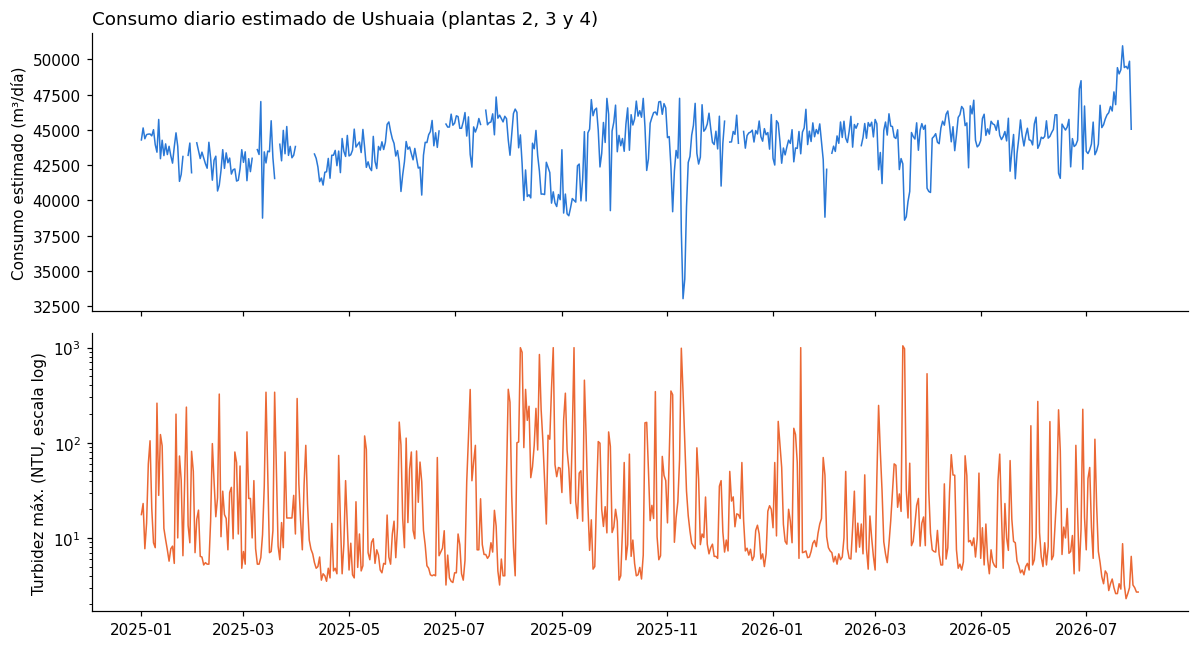

In [12]:
# serie de consumo y turbidez
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8985"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(D.index, D.cons, color=AZUL, lw=1)
ax[0].set_ylabel("Consumo estimado (m³/día)")
ax[0].set_title("Consumo diario estimado de Ushuaia (plantas 2, 3 y 4)", loc="left")
ax[1].plot(D.index, D.turb_max, color=NARANJA, lw=1)
ax[1].set_yscale("log")
ax[1].set_ylabel("Turbidez máx. (NTU, escala log)")
fig.tight_layout()
fig.savefig(FIG / "c01_serie_consumo.png")
plt.show()

**Interpretación.** El consumo estimado se mueve en una franja angosta: en el 90 % de los días está entre 40.000 y 47.000 m³, con una leve suba entre 2025 y 2026. La turbidez es casi siempre baja, pero tiene picos aislados muy altos. Los picos que llegan a ≈ 1.000 NTU son lecturas en el tope del sensor (999), es decir, la turbidez real fue igual o mayor. Son pocos: 1 día en la Planta 2, 3 en la Planta 3 y 1 en la Planta 4.

La turbidez se representa en escala logarítmica porque, en escala normal, los picos aplastan la línea y los valores habituales no se distinguen. Es solo una decisión para poder ver el gráfico; no cambia los datos.

### 7.2 Validación de la estimación: ritmo diario y semanal
Para comprobar que el balance representa consumo real se calcula, en cada planta, el consumo medio de cada franja horaria (lecturas de 2 horas) y el consumo diario por día de la semana. Una ciudad consume menos de madrugada y más de día.

Planta 2: mínimo a las 6 h (1,836 m³) | máximo a las 22 h (2,423 m³)
Planta 3: mínimo a las 4 h (799 m³) | máximo a las 14 h (1,016 m³)
Planta 4: mínimo a las 6 h (443 m³) | máximo a las 2 h (543 m³)


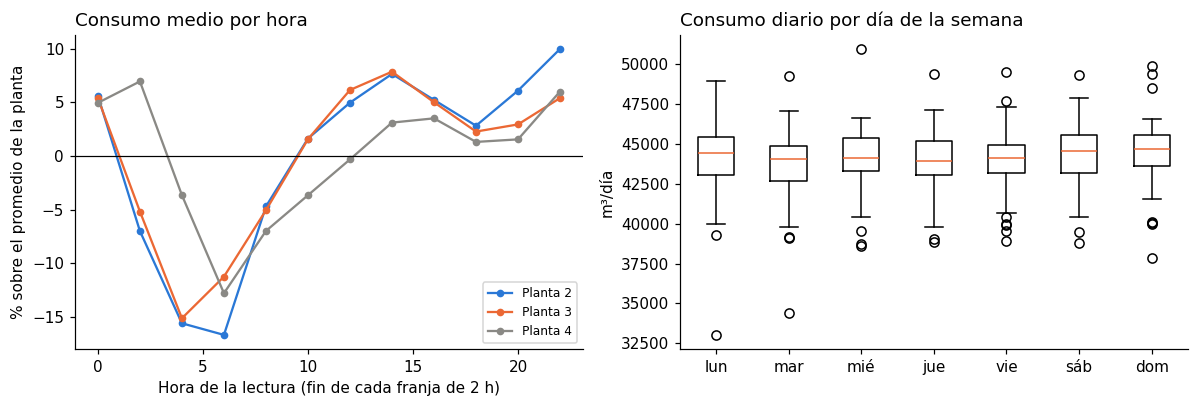

In [13]:
# perfil horario de cada planta y consumo por día de la semana
D2 = D.dropna(subset=["cons"]).copy()
D2["dow"] = D2.index.dayofweek
nombres = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
colores = {2: AZUL, 3: NARANJA, 4: GRIS}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for p, d in plantas.items():
    c2h = d.caudal_ls * 7.2 - d.vol.diff()                  # 1 L/s durante 2 horas = 7,2 m³
    perfil = c2h.groupby(c2h.index.hour).mean()
    ax[0].plot(perfil.index, (perfil / perfil.mean() - 1) * 100, marker="o", ms=4,
               color=colores[p], label=f"Planta {p}")
    print(f"Planta {p}: mínimo a las {perfil.idxmin()} h ({perfil.min():,.0f} m³) | máximo a las {perfil.idxmax()} h ({perfil.max():,.0f} m³)")
ax[0].axhline(0, color="k", lw=.8)
ax[0].set_xlabel("Hora de la lectura (fin de cada franja de 2 h)"); ax[0].set_ylabel("% sobre el promedio de la planta")
ax[0].set_title("Consumo medio por hora", loc="left"); ax[0].legend(fontsize=8)
ax[1].boxplot([D2[D2.dow == k].cons for k in range(7)], medianprops=dict(color=NARANJA))
ax[1].set_xticklabels(nombres)
ax[1].set_title("Consumo diario por día de la semana", loc="left"); ax[1].set_ylabel("m³/día")
fig.tight_layout(); fig.savefig(FIG / "c02_perfil_horario_semana.png"); plt.show()

**Interpretación.** Las plantas 2 y 3 tienen casi la misma curva: el consumo es mínimo de madrugada (franjas que terminan a las 4 y a las 6 h, unos 15 % bajo su promedio) y más alto de la tarde a la noche. Es el ritmo que se espera en una ciudad y es coherente con que el balance esté midiendo consumo real. La Planta 4 también tiene su mínimo a las 6 h, pero su máximo cae en la franja de las 0 a las 2 h y el consumo se mantiene alto de la noche a la madrugada. Ese patrón se repite en todo el período y no depende del día de la semana; no sé a qué se debe, puede incluir agua no contabilizada y lo tengo que confirmar con operaciones.

En el gráfico de cajas, el consumo diario es parecido todos los días de la semana. Los puntos fuera de las cajas son días alejados del rango habitual: no los eliminé, son días reales y poco frecuentes.

### 7.3 Consumo según el día de la semana
Se compara el consumo de cada día con el promedio de su propia semana (ventana centrada de 7 días), para separar el efecto del día de la semana de la tendencia general. Las barras muestran el promedio de cada día; la línea vertical de cada barra indica el rango donde probablemente está el promedio real (intervalo de confianza del 95 %).

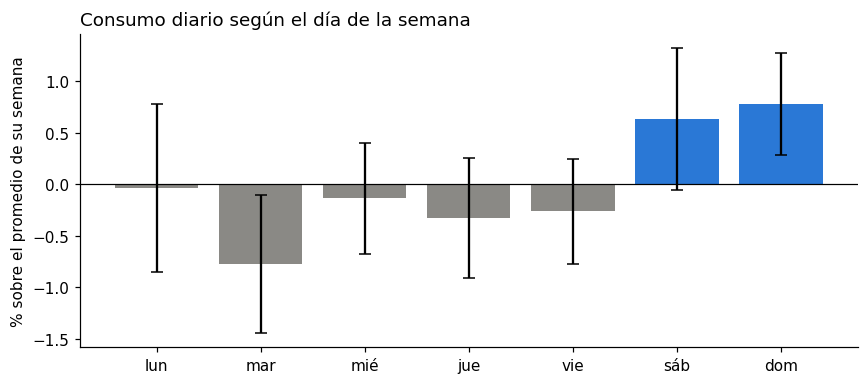

Fin de semana: +0.71 % | lunes a viernes: -0.31 %
Variación típica entre días (desvío del consumo): 4.5%


In [14]:
# ¿cómo cambia el consumo según el día de la semana?
D["dow"] = D.index.dayofweek
# desvío de cada día respecto del promedio de su propia semana (centrado en 7 días), en %
D["rel"] = (D.cons / D.cons.rolling(7, center=True, min_periods=5).mean() - 1) * 100
nombres = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]

g = D.groupby("dow").rel
media, ic = g.mean(), 1.96 * g.std() / np.sqrt(g.count())      # media e intervalo de confianza 95 %
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(nombres, media, yerr=ic, color=[GRIS]*5 + [AZUL]*2, capsize=4)
ax.axhline(0, color="k", lw=.8); ax.set_ylabel("% sobre el promedio de su semana")
ax.set_title("Consumo diario según el día de la semana", loc="left")
fig.tight_layout(); fig.savefig(FIG / "c06_dia_semana.png"); plt.show()


finde = D[D.dow >= 5].rel.dropna(); sem = D[D.dow < 5].rel.dropna()
print(f"Fin de semana: {finde.mean():+.2f} % | lunes a viernes: {sem.mean():+.2f} %")
print(f"Variación típica entre días (desvío del consumo): {D.cons.std()/D.cons.mean():.1%}")

Interpretación. El consumo casi no depende del día de la semana. Comparando cada día con el promedio de su propia semana, el domingo es el más alto (+0,8 %) y el martes el más bajo (−0,8 %); el sábado también está algo por encima (+0,6 %). En promedio, los fines de semana están un 0,7 % por encima del promedio de su semana y los días hábiles un 0,3 % por debajo: una diferencia de alrededor de 1 punto, unos 450 m³ sobre ≈ 44.000. Es chica frente a la variación típica entre días, que es del 4,5 % (≈ 2.000 m³). Por eso se espera que el calendario aporte poco a la predicción.

### 7.4 Perfil horario según el día de la semana
Con las lecturas de 2 horas de las tres plantas se calcula el consumo medio de cada franja horaria para lunes a viernes, sábado y domingo. El mapa de calor muestra cuánto se aparta cada franja de su promedio.

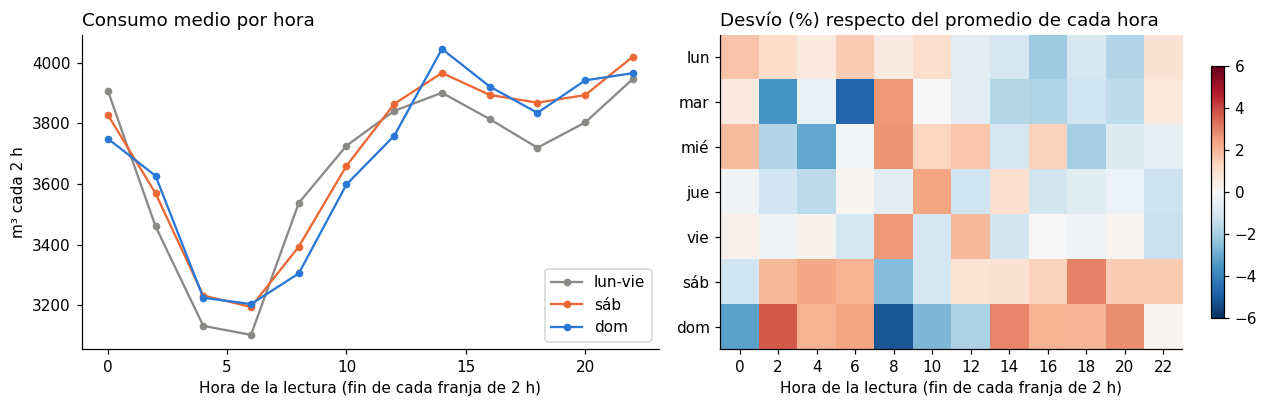

8-10 h | domingo: 3451 m³ | lunes a viernes: 3631 m³
14 h   | domingo: 4046 m³ | lunes a viernes: 3901 m³


In [15]:
# perfil horario de la ciudad según día de la semana (lecturas de 2 h, suma de las 3 plantas)
c2h = pd.concat([(d.caudal_ls * 7.2 - d.vol.diff()).rename(p) for p, d in plantas.items()], axis=1)
c2h = c2h[c2h.index <= FIN].sum(axis=1, min_count=3)
t = pd.DataFrame({"c": c2h}).dropna()
t["h"], t["dow"] = t.index.hour, t.index.dayofweek
t["grupo"] = np.where(t.dow < 5, "lun-vie", np.where(t.dow == 5, "sáb", "dom"))


fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for gname, col in [("lun-vie", GRIS), ("sáb", NARANJA), ("dom", AZUL)]:
    s = t[t.grupo == gname].groupby("h").c.mean()
    ax[0].plot(s.index, s.values, marker="o", ms=4, color=col, label=gname)
ax[0].set_xlabel("Hora de la lectura (fin de cada franja de 2 h)"); ax[0].set_ylabel("m³ cada 2 h"); ax[0].legend(); ax[0].set_title("Consumo medio por hora", loc="left")

t["rel"] = (t.c / t.groupby("h").c.transform("mean") - 1) * 100       # % sobre el promedio de esa hora
mapa = t.groupby(["dow", "h"]).rel.mean().unstack()
im = ax[1].imshow(mapa, cmap="RdBu_r", vmin=-6, vmax=6, aspect="auto")
ax[1].set_yticks(range(7)); ax[1].set_yticklabels(nombres); ax[1].set_xticks(range(12)); ax[1].set_xticklabels(mapa.columns)
ax[1].set_xlabel("Hora de la lectura (fin de cada franja de 2 h)"); ax[1].set_title("Desvío (%) respecto del promedio de cada hora", loc="left")
fig.colorbar(im, ax=ax[1], shrink=.8); fig.tight_layout()
fig.savefig(FIG / "c07_perfil_horario_dia_semana.png"); plt.show()

m = t[t.h.isin([8, 10])]
print("8-10 h | domingo:", round(m[m.dow == 6].c.mean()), "m³ | lunes a viernes:", round(m[m.dow < 5].c.mean()), "m³")
p = t[t.h == 14]
print("14 h   | domingo:", round(p[p.dow == 6].c.mean()), "m³ | lunes a viernes:", round(p[p.dow < 5].c.mean()), "m³")

**Interpretación.** El total diario es parecido todos los días, pero cambia la forma del día. En todos hay un mínimo de madrugada (franjas que terminan a las 4 y 6 h) y un consumo alto de la tarde a la noche. Lo que cambia es cuándo arranca: los domingos el consumo sube más tarde (en las franjas que terminan a las 8 y 10 h se consumen ≈ 3.450 m³ contra ≈ 3.630 de lunes a viernes, ≈ 5 % menos) y en la que termina a las 14 h ocurre lo inverso (≈ 4.050 contra ≈ 3.900, ≈ 4 % más). Los desvíos del mapa de calor son chicos (menos del 6 %). Para predecir el consumo total del día siguiente este efecto casi no importa, porque se compensa a lo largo del día; sería relevante para una predicción por franja horaria, que queda como trabajo futuro.

### 7.5 Feriados y fiestas de fin de año
Se compara el consumo de los feriados (nacionales y locales) que caen de lunes a viernes con el de los días laborables normales, y se observa en detalle el período de Nochebuena a Año Nuevo. Hay un solo año con estas fechas, por lo que los resultados son descriptivos y no permiten generalizar.

Feriados de lunes a viernes (n=22): -0.29 % | laborables normales: -0.31 %
               cons  rel
fecha_hora              
2025-12-24  45626.4  2.0
2025-12-25  44512.6 -0.7
2025-12-31  46086.5  4.0
2026-01-01  42983.9 -3.3
2026-01-02  42505.0 -4.2


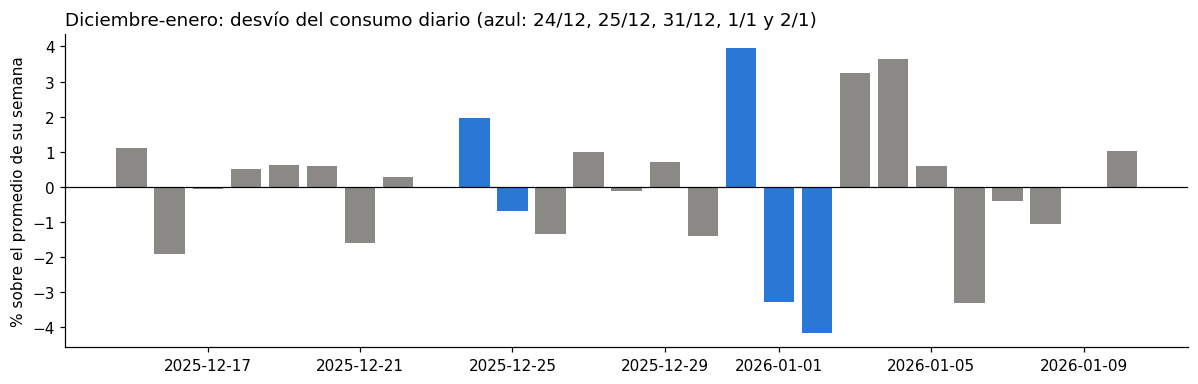

In [16]:
# feriados y fiestas
# Feriados del período (nacionales, y locales: Día de la Provincia y Día de Ushuaia). Fuente: calendario oficial de feriados
feriados = {"2025-01-01": "Año Nuevo", "2025-03-03": "Carnaval", "2025-03-04": "Carnaval", "2025-03-24": "Día de la Memoria",
            "2025-04-02": "Malvinas", "2025-04-18": "Viernes Santo", "2025-05-01": "Día del Trabajador", "2025-05-25": "Revolución de Mayo",
            "2025-06-01": "Día de la Provincia", "2025-06-16": "Güemes", "2025-06-20": "Día de la Bandera",
            "2025-07-09": "Día de la Independencia", "2025-10-12": "Día de Ushuaia", "2025-11-24": "Soberanía Nacional",
            "2025-12-08": "Inmaculada Concepción", "2025-12-25": "Navidad",
            "2026-01-01": "Año Nuevo", "2026-02-16": "Carnaval", "2026-02-17": "Carnaval", "2026-03-24": "Día de la Memoria",
            "2026-04-02": "Malvinas", "2026-04-03": "Viernes Santo", "2026-05-01": "Día del Trabajador",
            "2026-05-25": "Revolución de Mayo", "2026-06-01": "Día de la Provincia", "2026-06-15": "Güemes",
            "2026-06-20": "Día de la Bandera", "2026-07-09": "Día de la Independencia"}
fer = pd.to_datetime(list(feriados))
D["feriado"] = D.index.isin(fer)
# se comparan solo feriados de lunes a viernes, para no mezclar el efecto del fin de semana
h = D[D.feriado & (D.dow < 5)].rel.dropna(); lab = D[(~D.feriado) & (D.dow < 5)].rel.dropna()
print(f"Feriados de lunes a viernes (n={len(h)}): {h.mean():+.2f} % | laborables normales: {lab.mean():+.2f} %")

# Nochebuena, Navidad, Nochevieja y Año Nuevo: ¿se nota?
fiestas = pd.to_datetime(["2025-12-24", "2025-12-25", "2025-12-31", "2026-01-01", "2026-01-02"])
print(D.loc[D.index.isin(fiestas), ["cons", "rel"]].round(1))

z = D.loc["2025-12-15":"2026-01-10"]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(z.index, z.rel, color=[AZUL if d in fiestas else GRIS for d in z.index])
ax.axhline(0, color="k", lw=.8); ax.set_ylabel("% sobre el promedio de su semana")
ax.set_title("Diciembre-enero: desvío del consumo diario (azul: 24/12, 25/12, 31/12, 1/1 y 2/1)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "c08_fiestas.png"); plt.show()



**Interpretación.** Los feriados que caen de lunes a viernes no se distinguen de un día hábil normal (−0,3 % contra −0,3 %, con 22 feriados). En las fiestas de fin de año sí se ve un patrón: Nochebuena (+2,0 %) y sobre todo Nochevieja (+4,0 %) están por encima de lo normal, el 1/1 y el 2/1 caen (−3,3 % y −4,2 %), y el 3 y 4/1 se recupera (+3,3 % y +3,6 %). Como hay un solo año con estas fechas, es una observación descriptiva y no una regla que pueda generalizarse.

### 7.6 Correlaciones con el consumo del día siguiente
Se calcula la correlación entre el consumo de mañana y las variables diarias disponibles hoy (consumo, turbidez, caudal, volumen almacenado, temperatura y humedad). Una correlación cercana a 1 o −1 indica una relación fuerte; cercana a 0, una relación débil. Es una asociación, no prueba causalidad.

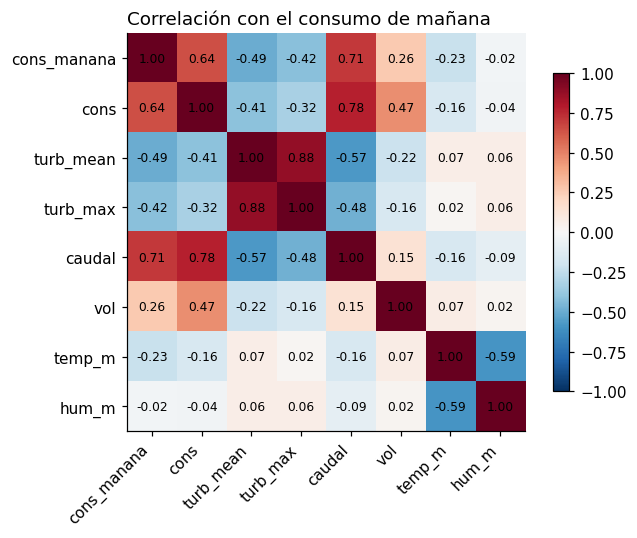

{'cons_manana': 1.0, 'cons': 0.64, 'turb_mean': -0.49, 'turb_max': -0.42, 'caudal': 0.71, 'vol': 0.26, 'temp_m': -0.23, 'hum_m': -0.02}


In [17]:
# correlaciones con el consumo del día siguiente
dd = D.copy()
dd["cons_manana"] = dd.cons.shift(-1)
cols = ["cons_manana", "cons", "turb_mean", "turb_max", "caudal", "vol", "temp_m", "hum_m"]
cm = dd[cols].corr()

fig, ax = plt.subplots(figsize=(6.4, 5))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right"); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, shrink=.8); ax.set_title("Correlación con el consumo de mañana", loc="left")
fig.tight_layout(); fig.savefig(FIG / "c03_correlaciones.png"); plt.show()
print(cm["cons_manana"].round(2).to_dict())

**Interpretación.** El consumo de mañana se relaciona sobre todo con el caudal de ingreso de hoy (r = 0,71) y con el consumo de hoy (0,64). Con la turbidez la relación es negativa (−0,49 con la media diaria y −0,42 con la máxima), con el volumen almacenado es baja (0,26) y con la temperatura (−0,23) y la humedad (−0,02) es casi nula. Como el consumo estimado incluye el caudal de ingreso y la turbidez lo reduce, parte de la relación con la turbidez puede venir de la forma de calcular el consumo y no de un cambio real en la demanda; la tomo como asociación, no como causa. La turbidez media y la máxima están muy relacionadas entre sí (0,88), así que aportan información parecida.

### 7.7 Distribución del consumo diario
Se grafica cómo se reparte el consumo de la ciudad entre los días del período.

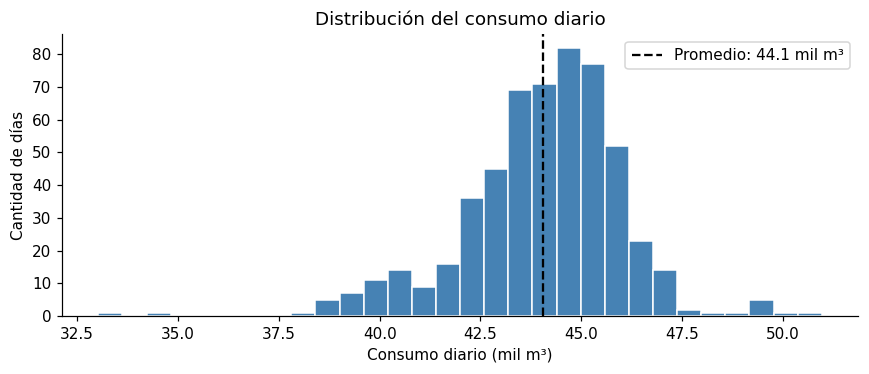

Mediana: 44,252 m³ | promedio: 44,052 m³ | desvío: 1,994 m³


In [18]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(D.cons.dropna() / 1000, bins=30, color="steelblue", edgecolor="white")
ax.axvline(D.cons.mean() / 1000, color="black", ls="--", label=f"Promedio: {D.cons.mean()/1000:.1f} mil m³")
ax.set_xlabel("Consumo diario (mil m³)")
ax.set_ylabel("Cantidad de días")
ax.set_title("Distribución del consumo diario")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Mediana: {D.cons.median():,.0f} m³ | promedio: {D.cons.mean():,.0f} m³ | desvío: {D.cons.std():,.0f} m³")

**Interpretación.** el promedio y la mediana casi coinciden y el desvío es de alrededor del 4,5 % del promedio. El consumo diario varía poco, y eso explica por qué un promedio de los últimos días ya es una referencia difícil de superar.

### 7.8 Consumo medio por mes
Se calcula el consumo medio diario de cada mes para ver si hay un patrón estacional.

            consumo medio (m³/día)  días con dato
fecha_hora                                       
2025-01                    43777.0             28
2025-02                    42595.0             27
2025-03                    43285.0             27
2025-04                    42732.0             20
2025-05                    43601.0             31
2025-06                    43927.0             28
2025-07                    45445.0             29
2025-08                    42306.0             31
2025-09                    42855.0             30
2025-10                    45516.0             31
2025-11                    43097.0             30
2025-12                    44621.0             27
2026-01                    44073.0             31
2026-02                    44607.0             25
2026-03                    43667.0             31
2026-04                    44817.0             30
2026-05                    44571.0             31
2026-06                    44766.0             30


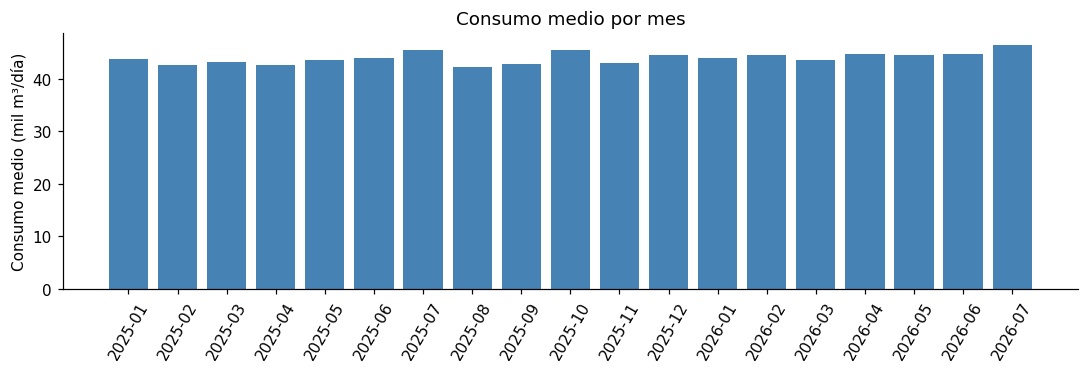

In [19]:
mensual = D.cons.groupby(D.index.to_period("M")).agg(["mean", "count"])
mensual["mean"] = mensual["mean"].round(0)
print(mensual.rename(columns={"mean": "consumo medio (m³/día)", "count": "días con dato"}))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(mensual.index.astype(str), mensual["mean"] / 1000, color="steelblue")
ax.set_ylabel("Consumo medio (mil m³/día)")
ax.set_title("Consumo medio por mes")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

**Interpretación.** Los promedios mensuales se mueven en un rango chico (entre 42.300 y 46.400 m³/día) y no se ve un ciclo claro. Con solo 19 meses, cada mes aparece una o dos veces. Por eso no se puede separar una estacionalidad anual de una tendencia, y por eso mes se usa como una variable más y no como una conclusión sobre el año.

## Conclusiones del análisis exploratorio

- **El consumo diario es estable.** El 90 % de los días se ubica entre 40.000 y 47.000 m³; el promedio es de 44.052 m³ y el desvío de 1.994 m³ (4,5 %). Por eso predecir "lo mismo que hoy" ya da un error bajo y es una referencia exigente.
- **El calendario aporta poco.** El día de la semana y los feriados cambian el consumo menos de 1 %, aunque la diferencia entre fin de semana y días hábiles sea estadísticamente detectable. Solo se ven desvíos puntuales en fechas como Nochebuena, Nochevieja y comienzos de enero.
- **El caudal y el consumo reciente son lo más ligado al consumo de mañana.** Correlaciones con el consumo del día siguiente: caudal de ingreso 0,71 y consumo de hoy 0,64.
- **La turbidez tiene una relación negativa** (−0,49 la media y −0,42 la máxima): con más turbidez, el consumo del día siguiente tiende a ser menor. Es una asociación y no se interpreta como causa.
- **El clima casi no aporta.** La temperatura se relaciona débilmente (−0,23) y la humedad prácticamente nada (−0,02).
- **Calidad de datos.** Los faltantes no se imputaron: los días sin dato quedan fuera. Las lecturas de caudal anómalas se marcaron y se anularon, conservando la original. Las lecturas de turbidez de 999 NTU se conservaron: indican que la turbidez superó el tope del sensor.

**C: Modelado, entrenamiento, prueba y conclusiones.**


## 8. Preparación de variables y partición temporal
Cada fila es un día. Todas las variables se calculan solo con información disponible hasta el final de ese día; únicamente el objetivo (consumo del día siguiente) mira hacia adelante. Armo cuatro conjuntos de variables, de menor a mayor información, para medir el aporte de cada grupo: A (consumo pasado y calendario), B (+ turbidez), C (+ caudal y volumen almacenado) y D (+ clima). Los cuatro conjuntos se evalúan sobre las mismas filas: descarto los días a los que les falta cualquier variable, sin completar nada. Los datos se separan en el tiempo: entrenamiento hasta el 29/04/2026 y prueba desde el 01/05/2026, sin mezcla aleatoria.

In [20]:
# variables y partición temporal
F = pd.DataFrame(index=D.index)
F["y"]          = D.cons.shift(-1)                                 # OBJETIVO: consumo del día siguiente
F["cons_hoy"]   = D.cons                                           # consumo del día que termina
F["cons_m7"]    = D.cons.rolling(7, min_periods=5).mean()          # promedio de los últimos 7 días
F["cons_l7"]    = D.cons.shift(6)                                  # mismo día de la semana que el que se predice
F["dow_sig"]    = (F.index.dayofweek + 1) % 7                      # día de la semana a predecir (categoría)
F["mes"]        = F.index.month                                    # mes (categoría)
F["turb_mean"], F["turb_max"] = D.turb_mean, D.turb_max
F["turb_max3"]  = D.turb_max.rolling(3, min_periods=1).max()       # turbidez máxima de los últimos 3 días
F["caudal"]     = D.caudal
F["vol_inicio"] = D.vol                                            # volumen almacenado a las 00:00 del día que termina
for c in ["temp_m", "temp_min", "temp_max", "hum_m"]:
    F[c] = D[c]
F["temp_m3"]    = D.temp_m.rolling(3, min_periods=2).mean()

A  = ["cons_hoy", "cons_m7", "cons_l7", "dow_sig", "mes"]
B  = A + ["turb_mean", "turb_max", "turb_max3"]
Cc = B + ["caudal", "vol_inicio"]
Dc = Cc + ["temp_m", "temp_min", "temp_max", "hum_m", "temp_m3"]
CONJ = {"A: consumo pasado + calendario": A, "B: A + turbidez": B,
        "C: B + caudal y volumen": Cc, "D: C + clima": Dc}

# Sin imputar: se descartan los días a los que les falta el objetivo o cualquier variable
antes = F.y.notna().sum()
F = F.dropna(subset=["y"] + Dc)
print(f"Días con objetivo: {antes} | descartados por algún faltante: {antes - len(F)} | quedan: {len(F)}")
print({k: len(v) for k, v in CONJ.items()})

# Partición temporal
tr = F[F.index < "2026-04-30"]
te = F[F.index >= "2026-05-01"]
print(f"Entrenamiento: {len(tr)} días ({tr.index.min().date()} a {tr.index.max().date()})")
print(f"Prueba:        {len(te)} días ({te.index.min().date()} a {te.index.max().date()})")
print(f"Consumo medio de prueba: {te.y.mean():,.0f} m³/día")

Días con objetivo: 544 | descartados por algún faltante: 42 | quedan: 502
{'A: consumo pasado + calendario': 5, 'B: A + turbidez': 8, 'C: B + caudal y volumen': 10, 'D: C + clima': 15}
Entrenamiento: 414 días (2025-01-07 a 2026-04-29)
Prueba:        87 días (2026-05-01 a 2026-07-26)
Consumo medio de prueba: 45,237 m³/día


**Interpretación.** Cada fila es un día y contiene solo información disponible al cierre de ese día; lo único que mira hacia adelante es el objetivo (el consumo de mañana). Las variables se agrupan en cuatro conjuntos para medir qué aporta cada grupo: A (consumo pasado y calendario, 5 variables), B (suma turbidez, 8), C (suma caudal y volumen, 10) y D (suma clima, 15). De los 544 días con objetivo descarté, sin completar, 42 a los que les faltaba algún dato (casi siempre el consumo de hoy, el promedio de 7 días o el consumo del mismo día de la semana anterior, porque arrastran los días sin consumo calculable): quedan 502 filas, 20 menos que con la imputación anterior. Los datos se dividen por fecha: 414 días de entrenamiento (07/01/2025 a 29/04/2026) y 87 de prueba (01/05/2026 a 26/07/2026). El 30/04 se excluye de ambos para que ninguna respuesta de entrenamiento caiga en el período de evaluación. El consumo medio del período de prueba es de ≈ 45.200 m³/día, la referencia para leer los errores.

**Diseño del experimento.**
- **Partición:** entrenamiento hasta el 29/04/2026 y prueba desde el 01/05/2026 (el 30/04 queda afuera).
- **Sin imputación:** no se completa ningún dato; los días incompletos quedan fuera.
- **Variables de calendario:** el día de la semana y el mes son categorías sin orden, por eso en Ridge y KNN se codifican con `OneHotEncoder` (una columna por categoría) en lugar de usarlos como números del 0 al 6 o del 1 al 12. Random Forest los usa como números, porque los árboles cortan por umbrales y no miden distancias.
- **Escalado:** Ridge y KNN estandarizan las variables numéricas con `StandardScaler`. Todo va dentro de un `Pipeline`, así que se ajusta solo con el entrenamiento (y, en la validación cruzada, solo con la parte de entrenamiento de cada partición).
- **Elección del modelo:** con búsqueda aleatoria de hiperparámetros y validación cruzada temporal **dentro del entrenamiento**. El período de prueba no interviene en ninguna elección: se usa una sola vez, al final, para medir el modelo elegido.

### 8.1 Referencias (baselines)
Antes de entrenar modelos se miden tres reglas simples que no aprenden de los datos: repetir el consumo de hoy (persistencia), usar el promedio de los últimos 7 días y usar el consumo del mismo día de la semana pasada. Estas referencias son el piso contra el cual se comparan los modelos: un modelo que no las supere no aporta valor. Se mide el error absoluto medio (MAE), la raíz del error cuadrático medio (RMSE) y el R².

In [21]:
# referencias simples, evaluadas en el período de prueba
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metricas(y, p):
    return dict(MAE=mean_absolute_error(y, p),
                RMSE=mean_squared_error(y, p) ** .5,
                R2=r2_score(y, p))

base = pd.DataFrame({
    "Persistencia (repite hoy)":        metricas(te.y, te.cons_hoy),
    "Promedio de 7 días":               metricas(te.y, te.cons_m7),
    "Mismo día de la semana pasada":    metricas(te.y, te.cons_l7)}).T.round(2)
base

,MAE,RMSE,R2
Persistencia (repite hoy),1126.78,1692.31,0.2
Promedio de 7 días,1091.36,1466.09,0.4
Mismo día de la semana pasada,1487.12,1885.88,0.0


**Interpretación.** Las tres referencias no aprenden nada: predicen el consumo de mañana con una regla fija. La mejor en el período de prueba es el promedio de los últimos 7 días, con un error medio (MAE) de ≈ 1.091 m³/día, alrededor del 2,4 % del consumo medio. Repetir el consumo de hoy da un MAE de ≈ 1.127 y usar el mismo día de la semana pasada es la peor opción (≈ 1.487), lo que concuerda con que el día de la semana influye poco. Como el consumo es muy estable, estas reglas simples ya son difíciles de superar: un modelo solo aporta si logra un error menor que ≈ 1.091 m³/día.

## 9. Modelos y resultados
Comparo tres modelos de regresión (Ridge, Random Forest y KNN) en cada uno de los cuatro conjuntos de variables. Los hiperparámetros se ajustan con búsqueda aleatoria (`RandomizedSearchCV`, 20 combinaciones) y validación cruzada temporal (`TimeSeriesSplit`, 5 particiones con 1 día de separación), usando solo el período de entrenamiento. La métrica para elegir es el error absoluto medio (MAE) de la validación cruzada.

- **Ridge**: regresión lineal con una penalización (alpha) que achica los coeficientes (Clase 4). Busco alpha entre 0,001 y 1.000 para que el valor elegido no quede en el borde del rango.
- **Random Forest**: promedia muchos árboles de decisión entrenados con variaciones de los datos (Clase 5).
- **KNN**: predice con el promedio de los días más parecidos (Clase 5); como mide distancias, las variables se estandarizan antes.

**Nota sobre las métricas.** Precisión, recall y F1 miden aciertos entre categorías y se usan en clasificación. Este proyecto es de regresión (se predice una cantidad en m³/día), por eso se evalúa con MAE (error medio en m³), RMSE (penaliza más los errores grandes) y R² (qué parte de la variación explica el modelo), siempre comparados con tres referencias simples.

In [22]:
# modelos y ajuste de hiperparámetros (solo con entrenamiento)
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

SEMILLA = 42
cv = TimeSeriesSplit(n_splits=5, gap=1)
CATEG = ["dow_sig", "mes"]                     # categorías sin orden

def preparar(cols):
    # one-hot para las categorías y estandarización para las numéricas (Ridge y KNN)
    cat = [c for c in cols if c in CATEG]
    num = [c for c in cols if c not in CATEG]
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
                              ("num", StandardScaler(), num)])

def espacio(cols):
    return {
        "Ridge": (make_pipeline(preparar(cols), Ridge()),
                  {"ridge__alpha": np.logspace(-3, 3, 40)}),
        "Random Forest": (RandomForestRegressor(random_state=SEMILLA),          # no necesita escalar ni one-hot
                          {"n_estimators": [200, 400], "max_depth": [3, 5, 8, None],
                           "min_samples_leaf": [3, 5, 10, 20]}),
        "KNN": (make_pipeline(preparar(cols), KNeighborsRegressor()),           # mide distancias: necesita escalar
                {"kneighborsregressor__n_neighbors": [3, 5, 7, 10, 12, 15, 20, 25, 30, 35, 40, 50]})}

res, mejores = [], {}
for conj, cols in CONJ.items():
    for nombre, (m, g) in espacio(cols).items():
        bus = RandomizedSearchCV(m, g, n_iter=20, cv=cv, scoring="neg_mean_absolute_error",
                                 random_state=SEMILLA, n_jobs=-1).fit(tr[cols], tr.y)
        mejores[(conj, nombre)] = bus.best_estimator_
        res.append(dict(Conjunto=conj, Modelo=nombre,
                        MAE_cv=-bus.best_score_,                                   # validación cruzada (para elegir)
                        MAE_train=mean_absolute_error(tr.y, bus.predict(tr[cols]))))
res = pd.DataFrame(res).round(2)
print("Error medio en validación cruzada temporal (m³/día) — es el que se usa para elegir")
res.pivot(index="Conjunto", columns="Modelo", values="MAE_cv")

Error medio en validación cruzada temporal (m³/día) — es el que se usa para elegir


Modelo,KNN,Random Forest,Ridge
Conjunto,,,
A: consumo pasado + calendario,1351.60,1387.64,1333.63
B: A + turbidez,1285.50,1284.62,1241.18
C: B + caudal y volumen,1210.44,1167.06,1111.78
D: C + clima,1292.79,1252.50,1181.39


In [23]:
# hiperparámetros elegidos y error de entrenamiento vs. validación cruzada
def texto_hp(nombre, m):
    if nombre == "Ridge": return f"alpha = {m[-1].alpha:.3f}"
    if nombre == "Random Forest": return f"{m.n_estimators} árboles, profundidad {m.max_depth}, mín. {m.min_samples_leaf} por hoja"
    return f"{m[-1].n_neighbors} vecinos"
hp = pd.DataFrame({nombre: {conj.split(":")[0]: texto_hp(nombre, m) for (conj, n2), m in mejores.items() if n2 == nombre}
                   for nombre in ["Ridge", "Random Forest", "KNN"]})
print(hp.to_string())
print("\nRango de alpha buscado en Ridge: 0,001 a 1.000")
print()
print("Error medio (m³/día): entrenamiento | validación cruzada")
print(res.pivot(index="Conjunto", columns="Modelo", values=["MAE_train", "MAE_cv"]).round(0).to_string())

            Ridge                                    Random Forest         KNN
A  alpha = 14.251  200 árboles, profundidad None, mín. 20 por hoja  10 vecinos
B  alpha = 58.780      400 árboles, profundidad 3, mín. 5 por hoja  12 vecinos
C  alpha = 58.780      400 árboles, profundidad 5, mín. 3 por hoja  12 vecinos
D  alpha = 14.251      200 árboles, profundidad 3, mín. 3 por hoja   5 vecinos

Rango de alpha buscado en Ridge: 0,001 a 1.000

Error medio (m³/día): entrenamiento | validación cruzada
                               MAE_train                        MAE_cv                      
Modelo                               KNN Random Forest   Ridge     KNN Random Forest   Ridge
Conjunto                                                                                    
A: consumo pasado + calendario    1032.0        1062.0  1089.0  1352.0        1388.0  1334.0
B: A + turbidez                   1003.0         938.0  1031.0  1286.0        1285.0  1241.0
C: B + caudal y volumen           

**Interpretación.** En la validación cruzada, Ridge tiene el menor error en los cuatro conjuntos de variables. En los tres modelos el mejor conjunto es el C (con caudal y volumen almacenado): Ridge baja de 1.334 m³/día con el conjunto A a 1.112 con el C. Sumar el clima (D) no ayuda: el error vuelve a subir (1.181 en Ridge). Ridge eligió alpha = 14,3 y 58,8, dentro del rango buscado, así que ya no queda en el borde.

Random Forest y KNN tienen un error de entrenamiento mucho menor que el de validación cruzada (por ejemplo, Random Forest con el conjunto C: 743 contra 1.167 m³/día). Eso es compatible con sobreajuste: aprenden detalles de los días de entrenamiento que no se repiten. En Ridge la diferencia es menor (936 contra 1.112).

### 9.1 Elección del modelo
Para que la comparación sea justa, las tres referencias simples se miden sobre **las mismas 5 particiones** de validación cruzada del entrenamiento que usó la búsqueda de hiperparámetros. El modelo elegido es el de menor error medio en esa validación cruzada. El período de prueba todavía no se mira.

In [24]:
# referencias simples en las mismas particiones de validación cruzada (solo entrenamiento) y elección del modelo
REFS = {"Persistencia (repite hoy)": "cons_hoy", "Promedio de 7 días": "cons_m7",
        "Mismo día de la semana pasada": "cons_l7"}
base_cv = pd.Series({n: np.mean([mean_absolute_error(tr.iloc[b].y, tr.iloc[b][c]) for a, b in cv.split(tr)])
                     for n, c in REFS.items()}).round(0)
print("Referencias simples — error medio en validación cruzada (m³/día):")
print(base_cv.to_string())

fila = res.loc[res.MAE_cv.idxmin()]
mejor = (fila.Conjunto, fila.Modelo)
mejor_ref = base_cv.idxmin()
mejora_cv = (1 - fila.MAE_cv / base_cv.min()) * 100
print(f"\nModelo elegido: {mejor[1]} con el conjunto {mejor[0]}  (MAE validación cruzada = {fila.MAE_cv:,.0f})")
print(f"Mejor referencia simple: {mejor_ref} (MAE = {base_cv.min():,.0f}) | diferencia: {mejora_cv:+.1f} %")

Referencias simples — error medio en validación cruzada (m³/día):
Persistencia (repite hoy)        1228.0
Promedio de 7 días               1323.0
Mismo día de la semana pasada    1774.0

Modelo elegido: Ridge con el conjunto C: B + caudal y volumen  (MAE validación cruzada = 1,112)
Mejor referencia simple: Persistencia (repite hoy) (MAE = 1,228) | diferencia: +9.5 %


**Interpretación.** El modelo elegido es **Ridge con el conjunto C** (consumo pasado, calendario, turbidez, caudal y volumen almacenado), con un error medio de 1.112 m³/día en la validación cruzada. En estas mismas particiones, la mejor regla simple es repetir el consumo de hoy (1.228), así que Ridge tiene un 9,5 % menos de error. Esta elección se hizo sin usar el período de prueba.

### 9.2 Evaluación final en el período de prueba
Recién ahora se usa el período de prueba (01/05 al 26/07/2026), una sola vez, para medir el modelo elegido contra las referencias simples. Para ser transparente, también se muestra cómo les fue a todos los modelos en la prueba, pero **ese resultado no se usa para elegir**: la elección ya se hizo en 9.1.

Período de prueba:
                                   MAE     RMSE    R2  % del consumo medio
Modelo elegido: Ridge (C)      1120.52  1520.58  0.35                  2.5
Persistencia (repite hoy)      1126.78  1692.31  0.20                  2.5
Promedio de 7 días             1091.36  1466.09  0.40                  2.4
Mismo día de la semana pasada  1487.12  1885.88  0.00                  3.3


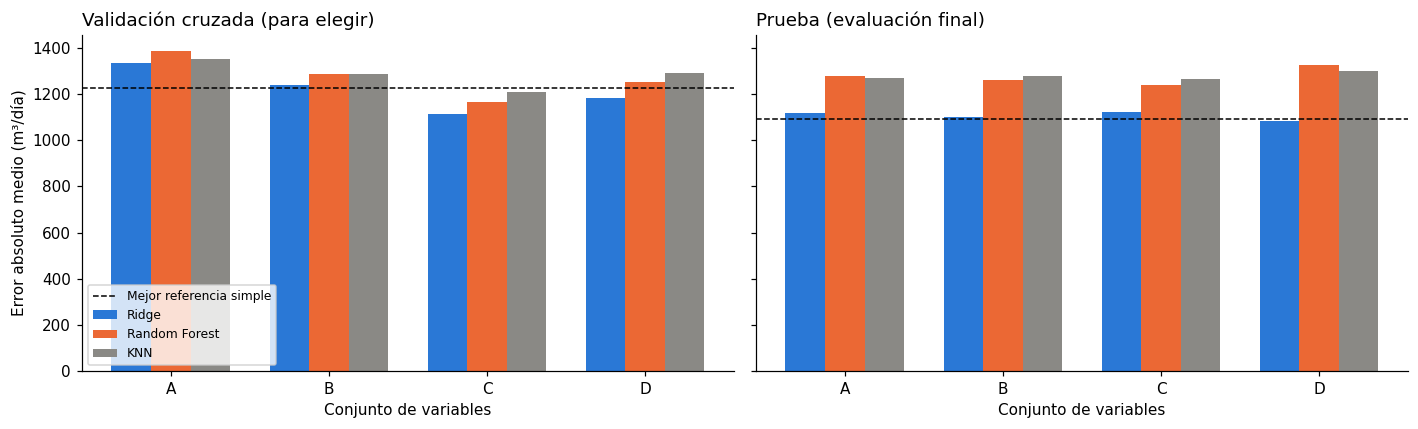

,Conjunto,Modelo,MAE_cv,MAE_train,MAE_test,RMSE_test,R2_test
6,C: B + caudal y volumen,Ridge,1111.78,935.59,1120.52,1520.58,0.35
7,C: B + caudal y volumen,Random Forest,1167.06,742.99,1239.75,1771.56,0.12
9,D: C + clima,Ridge,1181.39,919.44,1084.91,1476.97,0.39
8,C: B + caudal y volumen,KNN,1210.44,929.94,1265.60,1794.76,0.10
3,B: A + turbidez,Ridge,1241.18,1031.36,1099.71,1494.09,0.37
10,D: C + clima,Random Forest,1252.50,890.76,1324.54,1892.44,-0.01
4,B: A + turbidez,Random Forest,1284.62,938.48,1259.96,1831.40,0.06
5,B: A + turbidez,KNN,1285.50,1003.02,1277.25,1782.58,0.11
11,D: C + clima,KNN,1292.79,864.85,1299.60,1765.48,0.13
0,A: consumo pasado + calendario,Ridge,1333.63,1089.43,1119.01,1504.26,0.36


In [25]:
# evaluación final en prueba (una sola vez)
pred = {k: m.predict(te[CONJ[k[0]]]) for k, m in mejores.items()}
res["MAE_test"]  = [mean_absolute_error(te.y, pred[(r.Conjunto, r.Modelo)]) for r in res.itertuples()]
res["RMSE_test"] = [mean_squared_error(te.y, pred[(r.Conjunto, r.Modelo)]) ** .5 for r in res.itertuples()]
res["R2_test"]   = [r2_score(te.y, pred[(r.Conjunto, r.Modelo)]) for r in res.itertuples()]
res = res.round(2)

final = pd.concat([pd.DataFrame({f"Modelo elegido: {mejor[1]} ({mejor[0].split(':')[0]})": metricas(te.y, pred[mejor])}).T,
                   base]).round(2)
final["% del consumo medio"] = (final.MAE / te.y.mean() * 100).round(1)
print("Período de prueba:")
print(final.to_string())

# gráfico: izquierda = validación cruzada (elección); derecha = prueba (evaluación final)
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True); w = .25
for ax, col, ref, tit in [(axs[0], "MAE_cv", base_cv.min(), "Validación cruzada (para elegir)"),
                          (axs[1], "MAE_test", base["MAE"].min(), "Prueba (evaluación final)")]:
    piv = res.pivot(index="Conjunto", columns="Modelo", values=col)[["Ridge", "Random Forest", "KNN"]]
    for i, (m, c) in enumerate(zip(piv.columns, [AZUL, NARANJA, GRIS])):
        ax.bar(np.arange(len(piv)) + (i - 1) * w, piv[m], w, label=m, color=c)
    ax.axhline(ref, color="k", ls="--", lw=1, label="Mejor referencia simple")
    ax.set_xticks(range(len(piv))); ax.set_xticklabels([c.split(":")[0] for c in piv.index])
    ax.set_title(tit, loc="left"); ax.set_xlabel("Conjunto de variables")
axs[0].set_ylabel("Error absoluto medio (m³/día)"); axs[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "c04_error_por_conjunto.png"); plt.show()
res.sort_values("MAE_cv")

**Interpretación.** En el período de prueba, Ridge con el conjunto C se equivoca en promedio 1.121 m³/día, el 2,5 % del consumo medio. Es apenas mejor que repetir el consumo de hoy (1.127) y un poco peor que el promedio de los últimos 7 días (1.091). Es decir: **en la prueba, el modelo elegido no supera a la mejor regla simple.**

Lo tomo como un resultado, no como un error. El consumo es tan estable que una regla simple ya es muy exigente. La mejora del 9,5 % que se vio en la validación cruzada no se repite en estos 87 días de otoño-invierno, así que no es una mejora firme. En la tabla completa, Ridge sigue siendo el mejor de los tres modelos con cada conjunto de variables, y Random Forest y KNN quedan por encima de las dos mejores reglas simples. Hay una combinación (Ridge con el conjunto D) que en la prueba da 1.085, pero no la elijo: elegirla mirando la prueba sería usar el período de evaluación para decidir, y en la validación cruzada fue peor que el conjunto C.

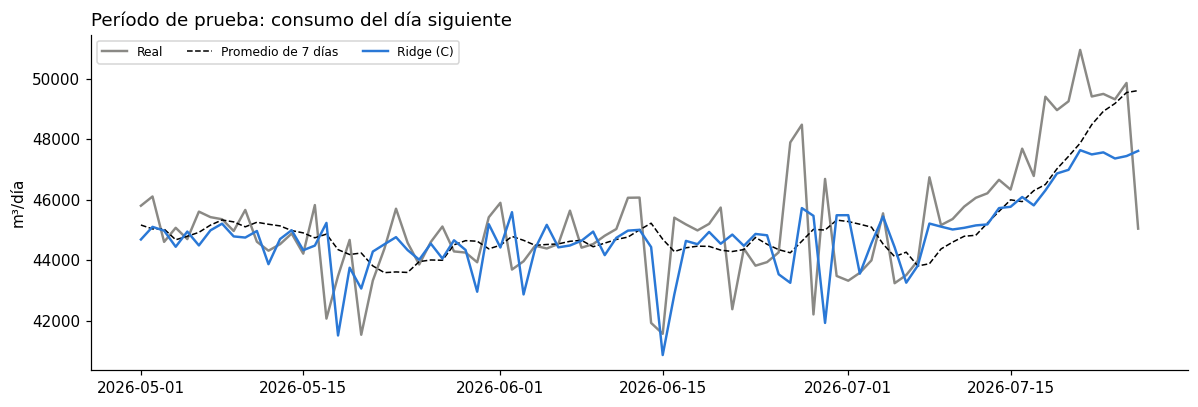

Coeficientes de Ridge (numéricas estandarizadas; día y mes en columnas one-hot), m³/día:


,0
caudal,807.86
cons_m7,370.97
turb_mean,-306.59
mes_10,177.45
dow_sig_1,-134.49
dow_sig_2,133.76
mes_2,-107.34
mes_5,-91.37
mes_7,90.47
vol_inicio,88.10


In [26]:
# predicción vs. realidad del modelo elegido y variables con más peso
etiqueta = f"{mejor[1]} ({mejor[0].split(':')[0]})"
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(te.index, te.y, color=GRIS, lw=1.6, label="Real")
ax.plot(te.index, te.cons_m7, color="k", lw=1, ls="--", label="Promedio de 7 días")
ax.plot(te.index, pred[mejor], color=AZUL, lw=1.6, label=etiqueta)
ax.set_ylabel("m³/día"); ax.set_title("Período de prueba: consumo del día siguiente", loc="left")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "c05_prediccion_test.png"); plt.show()

modelo = mejores[mejor]
if mejor[1] == "Ridge":
    nombres = [n.split("__", 1)[1] for n in modelo[:-1].get_feature_names_out()]
    peso = pd.Series(modelo[-1].coef_, index=nombres)
    print("Coeficientes de Ridge (numéricas estandarizadas; día y mes en columnas one-hot), m³/día:")
elif mejor[1] == "Random Forest":
    peso = pd.Series(modelo.feature_importances_, index=CONJ[mejor[0]])
    print("Importancia de cada variable en Random Forest:")
else:
    peso = pd.Series(dtype=float)
    print("KNN no tiene coeficientes: predice con el promedio de los días más parecidos.")
peso.sort_values(key=abs, ascending=False).round(2).head(12)

**Interpretación.** En Ridge con el conjunto C (variables numéricas estandarizadas) pesan más el caudal de ingreso (+808) y el promedio de consumo de los últimos 7 días (+371). La turbidez media resta (−307): con más turbidez, el modelo predice un consumo menor. Esto concuerda con que la turbidez reduce el agua que entra y, por cómo está calculado, el consumo estimado. El volumen almacenado suma poco (+88). El día de la semana y el mes aparecen como varias columnas one-hot con pesos menores (hasta ≈ 180). El de octubre (+177) refleja un solo octubre en el entrenamiento, no una regla del año. Estos coeficientes muestran qué variables usa el modelo, no causas. Como el consumo se estima a partir del caudal, es esperable que estén muy ligados.

En el gráfico del período de prueba, el modelo acompaña los días habituales, pero subestima la suba de fines de julio: se apoya en el pasado reciente y no anticipa los cambios bruscos.

### 9.3 Análisis de errores

Error medio (sesgo): +433 m³/día | error absoluto medio: 1,121 m³/día
Días con error menor a 1.000 m³: 56% | menor a 2.000 m³: 82%
Error máximo: 4,768 m³ el 2026-06-29
Error absoluto medio según el nivel de consumo real:
y
consumo bajo     1096.0
consumo medio     515.0
consumo alto     1750.0


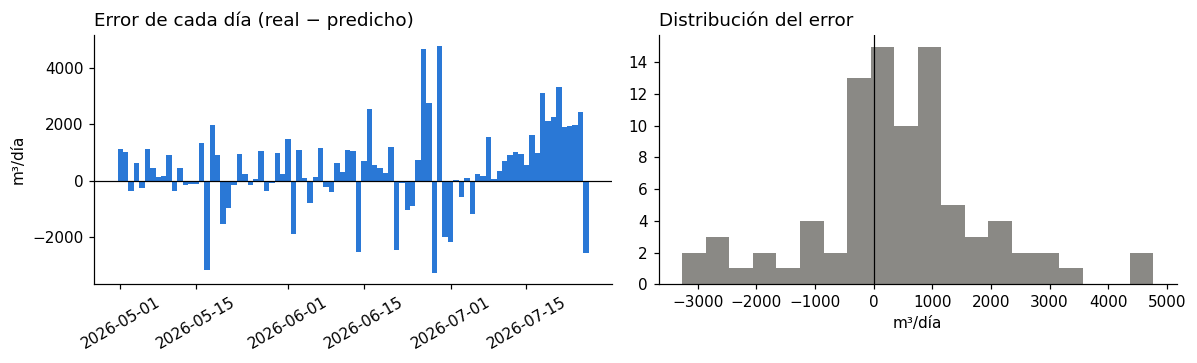

In [27]:
# análisis de errores del modelo elegido en el período de prueba
err = te.y - pd.Series(pred[mejor], index=te.index)          # error = real - predicho (m³/día)
print(f"Error medio (sesgo): {err.mean():+.0f} m³/día | error absoluto medio: {err.abs().mean():,.0f} m³/día")
print(f"Días con error menor a 1.000 m³: {(err.abs() < 1000).mean():.0%} | menor a 2.000 m³: {(err.abs() < 2000).mean():.0%}")
print(f"Error máximo: {err.abs().max():,.0f} m³ el {err.abs().idxmax().date()}")
rango = pd.qcut(te.y, 3, labels=["consumo bajo", "consumo medio", "consumo alto"])
print("Error absoluto medio según el nivel de consumo real:"); print(err.abs().groupby(rango).mean().round(0).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(err.index, err.values, color=AZUL, width=1); ax[0].axhline(0, color="k", lw=.8)
ax[0].set_title("Error de cada día (real − predicho)", loc="left"); ax[0].set_ylabel("m³/día"); ax[0].tick_params(axis="x", rotation=30)
ax[1].hist(err, bins=20, color=GRIS); ax[1].axvline(0, color="k", lw=.8)
ax[1].set_title("Distribución del error", loc="left"); ax[1].set_xlabel("m³/día")
fig.tight_layout(); fig.savefig(FIG / "c10_errores.png"); plt.show()

**Interpretación.** En el período de prueba el error absoluto medio es de 1.121 m³/día; en el 56 % de los días el error es menor a 1.000 m³ y en el 82 % menor a 2.000. El error medio con signo es de +433 m³: en promedio el modelo predice un poco menos de lo que ocurrió, sobre todo en la suba de fines de julio. El error máximo fue de 4.768 m³, el 29/06/2026. El error es menor en los días de consumo medio (≈ 515 m³) y mayor en los extremos, bajos (≈ 1.100) y sobre todo altos (≈ 1.750): el modelo se apoya en el pasado reciente y no anticipa los saltos bruscos.

### 9.4 Una predicción concreta

In [28]:
# una predicción concreta: cómo llega el modelo elegido al valor de un día
dia = te.index[40]
cols = CONJ[mejor[0]]
x = te.loc[[dia], cols]
print(f"Se conoce hasta el {dia.date()} y se predice el consumo del {(dia + pd.Timedelta(days=1)).date()}")
if mejor[1] == "Ridge":
    xs = modelo[:-1].transform(x)                                # one-hot y estandarización, como en el entrenamiento
    aporte = pd.Series(xs[0] * modelo[-1].coef_, index=nombres)  # peso de cada columna x su valor transformado
    print(f"Valor base del modelo (intercepto): {modelo[-1].intercept_:,.0f} m³")
    print("Aportes principales (m³):"); print(aporte.sort_values(key=abs, ascending=False).head(5).round(0).to_string())
    print("Control (valor base + suma de aportes):", round(modelo[-1].intercept_ + aporte.sum()))
print(f"Predicción: {modelo.predict(x)[0]:,.0f} m³ | consumo real: {te.loc[dia, 'y']:,.0f} m³ | promedio de 7 días: {te.loc[dia, 'cons_m7']:,.0f} m³")

Se conoce hasta el 2026-06-10 y se predice el consumo del 2026-06-11
Valor base del modelo (intercepto): 43,815 m³
Aportes principales (m³):
cons_m7       194.0
caudal        139.0
vol_inicio     88.0
dow_sig_3     -62.0
turb_max      -47.0
Control (valor base + suma de aportes): 44167
Predicción: 44,167 m³ | consumo real: 44,809 m³ | promedio de 7 días: 44,565 m³


**Interpretación.** Con lo conocido hasta el 10/06/2026, el modelo parte de su valor base (43.815 m³) y suma el aporte de cada variable: promedio de 7 días (+194), caudal (+139) y volumen almacenado (+88), y resta el día de la semana (−62) y la turbidez máxima (−47). La predicción para el 11/06 es de 44.167 m³. El consumo real fue de 44.809 m³ (error de 642 m³), mientras que el promedio de 7 días daba 44.565 m³ (error de 244 m³). En este día la regla simple estuvo más cerca: es un ejemplo concreto de lo que muestra la evaluación, que el modelo no le gana de forma clara.

## 10. Análisis complementario: turbidez y reservas (Planta 3)
Las secciones anteriores muestran que la turbidez aporta poco para predecir el consumo. Sin embargo, la hipótesis de partida era que el agua más turbia obliga a tratarla más tiempo y reduce el ingreso a las cisternas, mientras el consumo continúa. Para comprobarlo se analiza el volumen almacenado de la Planta 3 (suma de sus 5 cisternas).

**Método.** Un *episodio* es la primera lectura con turbidez ≥ 30 NTU (≈ percentil 95) sin otra lectura así en las 24 h anteriores, para no contar el mismo evento varias veces. Para cada episodio se calcula el cambio de volumen en las 24 h siguientes y se lo compara con el cambio habitual a esa misma hora del día (calculado en momentos sin turbidez alta), para no confundir el efecto con el ciclo normal de consumo. Se informa un intervalo de confianza del 95 %. Las lecturas de 999 NTU (tope del sensor) se conservan: la turbidez fue de 999 NTU o más, así que cuentan como turbidez alta.

Episodios: 68 (66 con dato a 24 h)
Cambio medio de volumen en 24 h: -465 m³
Descontando lo habitual: -522 m³ (IC 95 %: -677 a -366)


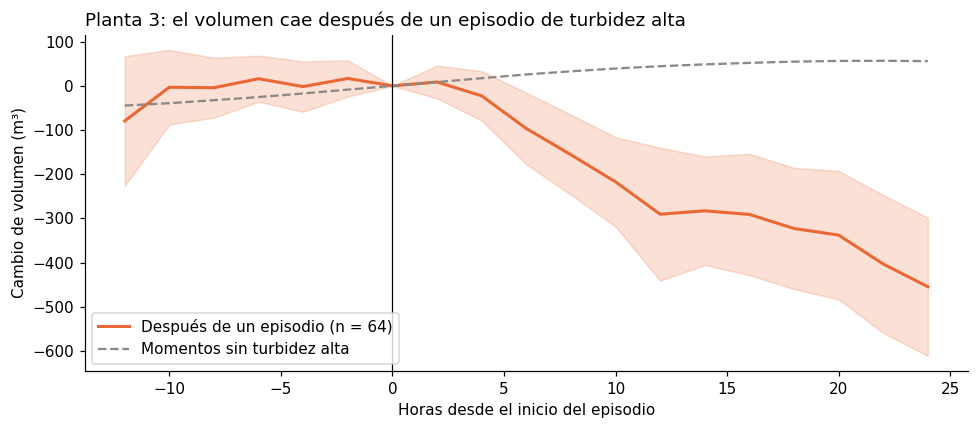

A +24 h: -455 m³ (banda 95 %: -611 a -298) | referencia: +56 m³


In [29]:
# Análisis complementario (Planta 3): ¿qué pasa con las reservas después de un episodio de turbidez alta?
d3 = plantas[3]
vol3 = d3["vol"]                                              # suma de las 5 cisternas de la Planta 3
turb3 = d3["turbidez_ntu"]                                    # 999 = tope del sensor (turbidez ≥ 999): se conserva

alta = turb3 >= 30                                            # umbral: ≈ percentil 95 de la turbidez
previa = alta.shift(1).rolling(12, min_periods=1).max().fillna(0).astype(bool)   # ¿hubo turbidez alta en las 24 h anteriores?
episodio = alta & ~previa                                     # primera lectura de cada episodio
normal = ~(turb3.rolling(12, min_periods=1).max() >= 30)      # momentos sin turbidez alta en las últimas 24 h

cambio24 = vol3.shift(-12) - vol3                             # cambio de volumen en las 24 h siguientes
habitual = cambio24[normal].groupby(cambio24[normal].index.hour).mean()   # cambio habitual a cada hora del día

e = cambio24[episodio].dropna()
dif = e.values - habitual.reindex(e.index.hour).values        # cambio del episodio menos lo habitual a esa hora
ic = 1.96 * dif.std(ddof=1) / np.sqrt(len(dif))
print(f"Episodios: {episodio.sum()} ({len(e)} con dato a 24 h)")
print(f"Cambio medio de volumen en 24 h: {e.mean():+.0f} m³")
print(f"Descontando lo habitual: {dif.mean():+.0f} m³ (IC 95 %: {dif.mean()-ic:+.0f} a {dif.mean()+ic:+.0f})")

# Trayectoria media alrededor del inicio del episodio (de -12 h a +24 h)
pasos = list(range(-6, 13))
variacion = pd.DataFrame({k: vol3.shift(-k) - vol3 for k in pasos})
tray = variacion[episodio].dropna(); ref = variacion[normal].mean()
horas = [k * 2 for k in pasos]; media = tray.mean(); ic_t = 1.96 * tray.std() / np.sqrt(len(tray))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(horas, media, color=NARANJA, lw=2, label=f"Después de un episodio (n = {len(tray)})")
ax.fill_between(horas, media - ic_t, media + ic_t, color=NARANJA, alpha=.2)
ax.plot(horas, ref, color=GRIS, ls="--", label="Momentos sin turbidez alta")
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Horas desde el inicio del episodio"); ax.set_ylabel("Cambio de volumen (m³)")
ax.set_title("Planta 3: el volumen cae después de un episodio de turbidez alta", loc="left"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "c09_turbidez_reservas.png"); plt.show()
print(f"A +24 h: {media[12]:+.0f} m³ (banda 95 %: {media[12]-ic_t[12]:+.0f} a {media[12]+ic_t[12]:+.0f}) | referencia: {ref[12]:+.0f} m³")

**Interpretación.** En 66 episodios (las lecturas de 999 NTU incluidas), el volumen de la Planta 3 bajó en promedio 522 m³ más de lo habitual en las 24 h siguientes (IC 95 %: 366 a 677 m³). Este resultado es compatible con la hipótesis de partida: como las secciones anteriores indican que la turbidez aporta poco a la predicción del consumo, lo que cambia es cuánta agua queda en reserva. No se midió directamente el ingreso, por lo que el mecanismo (más tiempo de tratamiento) es una explicación posible, no una comprobación. Es una asociación, no una causa: la turbidez suele coincidir con lluvias o deshielo, que pueden afectar otras variables. Además, se basa en solo 66 episodios y en un umbral (30 NTU) que no se comparó con otros.

## 11. Conclusiones, limitaciones y trabajo futuro

**Cómo respondió el modelo al problema planteado.** Pude estimar el consumo diario de la ciudad por balance entre el agua que ingresa a las plantas 2, 3 y 4 y la variación del volumen de las cisternas, y predecir el consumo del día siguiente con un error de alrededor del 2,5 % del consumo diario. El modelo elegido por validación cruzada fue Ridge con caudal y volumen almacenado (conjunto C). Frente a la mejor regla simple, tuvo un 9,5 % menos de error en la validación cruzada, pero en la prueba no la superó: quedó prácticamente igual que repetir el consumo de hoy y un poco por encima del promedio de 7 días.

**Conclusiones**
1. El consumo se puede estimar por balance, y la estimación es coherente con el ritmo diario de una ciudad (mínimo de madrugada y máximo a la tarde en las plantas 2 y 3).
2. El consumo diario es muy estable (≈ 44.000 m³/día, con una variación típica del 4,5 %). El día de la semana y los feriados casi no lo modifican. Las fiestas de fin de año muestran un patrón, con un solo año de observación.
3. El mejor de los tres modelos es Ridge, y el conjunto con caudal y volumen es el que más baja el error. Pero su ventaja sobre una regla simple no es firme: aparece en la validación cruzada y no en la prueba. Random Forest y KNN no superan a las reglas simples y rinden mucho mejor en entrenamiento que en validación, lo que es compatible con sobreajuste.
4. Lo que más usa el modelo es el caudal de ingreso y el consumo de la última semana; la turbidez media resta y el calendario y el clima pesan poco. Los coeficientes muestran qué variables usa el modelo, no causas.
5. El error es mayor en los días de consumo extremo, sobre todo los altos, porque el modelo no anticipa los saltos bruscos.
6. En la Planta 3, después de un episodio de turbidez alta, el volumen almacenado baja ≈ 520 m³ más de lo habitual en 24 h. Es una asociación, con solo 66 episodios y un umbral (30 NTU) que no comparé con otros.

**Limitaciones**
- El consumo es una estimación por balance y no una medición; usa el caudal de agua cruda, por lo que incluye pérdidas de proceso, fugas y otros usos no medidos.
- Se asume que las cisternas con lectura representan el almacenamiento de cada planta y que no hay doble conteo entre plantas (a confirmar con operaciones).
- El período es de 19 meses y la prueba, de solo 87 días de otoño-invierno: las diferencias entre modelos son chicas y podrían cambiar con más datos y otras estaciones.
- La relación entre consumo estimado y turbidez puede deberse en parte a la forma de calcularlo.
- No se usó la precipitación por tener datos incompletos, y hay un solo año de fiestas y feriados.
- Pendiente de confirmar con operaciones: los caudales en cero, el patrón nocturno de la Planta 4 y los días de baja producción de noviembre de 2025.

**Trabajo futuro**
- Incorporar precipitaciones y el pronóstico del día siguiente.
- Usar datos de medidores (anonimizados) para estimar el consumo por tipo de usuario.
- Predecir por franja horaria y con un horizonte de varios días.
- Predecir cuánto bajan las cisternas después de un episodio de turbidez.
- Validar la estimación con operaciones y sumar la Planta 1 si vuelve a funcionar.